In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
#from utils import *
#from utils_cpdir import *
from utils_experiments import *
from utils_mvcp import *
from utils import *
import os
from tqdm import tqdm
import warnings

In [2]:
warnings.filterwarnings("ignore")

# Reference Libraries

rebecca_data_ir = pd.read_csv('processed_data_new/rebecca_data_ir_final.csv')
del rebecca_data_ir['Unnamed: 0']
rebecca_data_ir.columns = list(np.float64(rebecca_data_ir.columns[:-4])) + list(rebecca_data_ir.columns[-4:])

rebecca_data_raman = pd.read_csv('processed_data_new/rebecca_data_raman_final_specy.csv')
del rebecca_data_raman['Unnamed: 0']
rebecca_data_raman.columns = list(np.float64(rebecca_data_raman.columns[:-4])) + list(rebecca_data_raman.columns[-4:])


# Process Data
poly_abbr_table = pd.read_excel('data_new/CCOPTIR_20240604_MixedMPsStdsv2_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:9,-5:-3]
poly_abbr_table.columns = ['polymer', 'abbr']

poly_and_comments_list = pd.read_excel('data_new/CCOPTIR_20240604_MixedMPsStdsv2_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:,9:13]

poly_list = list(np.unique(rebecca_data_raman['polymer'])) + ['LDPE']

notes_mix_std_fluor = pd.read_excel('data_new/MVCP_20241206_RP_AllCCOPTIRData_FluorescenceOnly.xlsx',
         sheet_name='MPs + Standards').iloc[:, [0,9,10,11,12]]
notes_mix_std_fluor.columns = ['id','polymer_ir', 'polymer_raman', 'polymer_overall', 'comments']
notes_mix_std_fluor = notes_mix_std_fluor.query('polymer_overall in @poly_list')
notes_mix_std_fluor_ids = np.array(notes_mix_std_fluor['id'])


IR_spectra_mix_std = pd.read_csv('processed_data_new/data_ir_mix_std_rebecca.csv')
del IR_spectra_mix_std['Unnamed: 0']
#non_bg = IR_spectra['background'] == 'no_background'
IR_spectra_mix_std.columns = list(np.float64(IR_spectra_mix_std.columns[:-8])) + list(IR_spectra_mix_std.columns[-8:])

IR_spectra_mix_std = (IR_spectra_mix_std.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(IR_spectra_mix_std.shape[1]-3))+[-1,-3,-2]])

IR_spectra_mix_std_rest = IR_spectra_mix_std.loc[[x not in poly_list 
                                                  for x in IR_spectra_mix_std['polymer']],:].reset_index(drop=True)
#IR_spectra_mix_std = IR_spectra_mix_std.loc[[x in ['LDPE', 'PP', 'PSL'] for x in IR_spectra_mix_std['polymer']],:].reset_index(drop=True)
IR_spectra_mix_std = IR_spectra_mix_std.loc[[x in poly_list 
                                             for x in IR_spectra_mix_std['polymer']],:].reset_index(drop=True)
IR_spectra_mix_std.loc[IR_spectra_mix_std['polymer'] == 'LDPE','polymer'] = 'PE'
IR_spectra_mix_std = IR_spectra_mix_std.sort_values('id').reset_index(drop=True)


Raman_spectra_mix_std = pd.read_csv('processed_data_new/data_raman_mix_std_rebecca_specy.csv')
#notes_mix_std_rest = np.array(Raman_spectra_mix_std['comments'])
notes_mix_std = Raman_spectra_mix_std.iloc[:,-5:]

notes_mix_std = (notes_mix_std.
                 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
                 drop(['polymer_x', 'abbr'], axis=1).
                 rename({'polymer_y':'polymer_overall'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_raman', right_on='abbr').
                 drop(['polymer_raman', 'abbr'], axis=1).
                 rename({'polymer':'polymer_raman'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_ir', right_on='abbr').
                 drop(['polymer_ir', 'abbr'], axis=1).
                 rename({'polymer':'polymer_ir'},axis=1))

notes_mix_std.loc[notes_mix_std['polymer_overall'] == 'LDPE','polymer_overall'] = 'PE'
notes_mix_std.loc[notes_mix_std['polymer_raman'] == 'LDPE','polymer_raman'] = 'PE'
notes_mix_std.loc[notes_mix_std['polymer_ir'] == 'LDPE','polymer_ir'] = 'PE'


#notes_mix_std_rest[[x is np.nan for x in notes_mix_std_rest]] = ''
del Raman_spectra_mix_std['Unnamed: 0']
Raman_spectra_mix_std.columns = list(np.float64(Raman_spectra_mix_std.columns[:-7])) + list(Raman_spectra_mix_std.columns[-7:])
Raman_spectra_mix_std = (Raman_spectra_mix_std.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(Raman_spectra_mix_std.shape[1]-5))+[-1,-2]])

#poly_and_comments_list_rest = poly_and_comments_list.loc[[x not in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

notes_mix_std = notes_mix_std.sort_values('id').reset_index(drop=True)
Raman_spectra_mix_std = Raman_spectra_mix_std.sort_values('id').reset_index(drop=True)

Raman_spectra_mix_std_rest = Raman_spectra_mix_std.loc[[x not in poly_list 
                                                        for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)
notes_mix_std_rest = notes_mix_std.loc[[x not in poly_list 
                                        for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

#poly_and_comments_list = poly_and_comments_list.loc[[x in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

notes_mix_std = notes_mix_std.loc[[x in poly_list 
                                   for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)
Raman_spectra_mix_std = Raman_spectra_mix_std.loc[[x in poly_list 
                                                   for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

Raman_spectra_mix_std.loc[Raman_spectra_mix_std['polymer'] == 'LDPE','polymer'] = 'PE'

ids_ideal_set = [(x in poly_list) and (y in poly_list) and (z in poly_list) 
                 for x, y, z in zip(notes_mix_std['polymer_raman'], 
                                    notes_mix_std['polymer_ir'], 
                                    notes_mix_std['polymer_overall'])]

ids_ideal_set = np.logical_and([x not in notes_mix_std_fluor_ids 
                                for x in Raman_spectra_mix_std['id']],
                               ids_ideal_set)

Raman_spectra_mix_std['id'] = ["mix_std_"+str(x) for x in Raman_spectra_mix_std['id']]
IR_spectra_mix_std['id'] = ["mix_std_"+str(x) for x in IR_spectra_mix_std['id']]

Raman_spectra_mix_std_ideal = Raman_spectra_mix_std.loc[ids_ideal_set,:].reset_index(drop=True)
IR_spectra_mix_std_ideal = IR_spectra_mix_std.loc[ids_ideal_set,:].reset_index(drop=True)

Raman_spectra_mix_std_lq = Raman_spectra_mix_std.loc[~ids_ideal_set,:].reset_index(drop=True)
IR_spectra_mix_std_lq = IR_spectra_mix_std.loc[~ids_ideal_set,:].reset_index(drop=True)

Raman_spectra_mix_std_lq = Raman_spectra_mix_std_lq.query('id != "mix_std_223"').reset_index(drop=True)
IR_spectra_mix_std_lq = IR_spectra_mix_std_lq.query('id != "mix_std_223"').reset_index(drop=True)



poly_abbr_table = pd.read_excel('data_new/CCOPTIR_20240326_MixedMPsv7.3_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:9,-5:-3]
poly_abbr_table.columns = ['polymer', 'abbr']

poly_and_comments_list = pd.read_excel('data_new/CCOPTIR_20240326_MixedMPsv7.3_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:,9:13]

poly_list = list(np.unique(rebecca_data_raman['polymer'])) + ['LDPE']

notes_mix_fluor = pd.read_excel('data_new/MVCP_20241206_RP_AllCCOPTIRData_FluorescenceOnly.xlsx',
         sheet_name='MPs Only').iloc[:, [0,9,10,11,12]]
notes_mix_fluor.columns = ['id','polymer_ir', 'polymer_raman', 'polymer_overall', 'comments']
notes_mix_fluor = notes_mix_fluor.query('polymer_overall in @poly_list')
notes_mix_fluor_ids = np.array(notes_mix_fluor['id'])


IR_spectra_mix = pd.read_csv('processed_data_new/data_ir_mix_rebecca.csv')
del IR_spectra_mix['Unnamed: 0']
#non_bg = IR_spectra['background'] == 'no_background'
IR_spectra_mix.columns = list(np.float64(IR_spectra_mix.columns[:-8])) + list(IR_spectra_mix.columns[-8:])

IR_spectra_mix = (IR_spectra_mix.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(IR_spectra_mix.shape[1]-3))+[-1,-3,-2]])

IR_spectra_mix_rest = IR_spectra_mix.loc[[x not in poly_list 
                                          for x in IR_spectra_mix['polymer']],:].reset_index(drop=True)
#IR_spectra_mix = IR_spectra_mix.loc[[x in ['LDPE', 'PP', 'PSL'] for x in IR_spectra_mix['polymer']],:].reset_index(drop=True)
IR_spectra_mix = IR_spectra_mix.loc[[x in poly_list 
                                     for x in IR_spectra_mix['polymer']],:].reset_index(drop=True)
IR_spectra_mix.loc[IR_spectra_mix['polymer'] == 'LDPE','polymer'] = 'PE'
IR_spectra_mix = IR_spectra_mix.sort_values('id').reset_index(drop=True)


#Raman_spectra_mix = pd.read_csv('processed_data_new/data_raman_mix_rebecca.csv')
Raman_spectra_mix = pd.read_csv('processed_data_new/data_raman_mix_rebecca_specy.csv')
#notes_mix_rest = np.array(Raman_spectra_mix['comments'])
notes_mix = Raman_spectra_mix.iloc[:,-5:]

notes_mix = (notes_mix.
                 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
                 drop(['polymer_x', 'abbr'], axis=1).
                 rename({'polymer_y':'polymer_overall'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_raman', right_on='abbr').
                 drop(['polymer_raman', 'abbr'], axis=1).
                 rename({'polymer':'polymer_raman'},axis=1).
                 merge(poly_abbr_table, left_on='polymer_ir', right_on='abbr').
                 drop(['polymer_ir', 'abbr'], axis=1).
                 rename({'polymer':'polymer_ir'},axis=1))

notes_mix.loc[notes_mix['polymer_overall'] == 'LDPE','polymer_overall'] = 'PE'
notes_mix.loc[notes_mix['polymer_raman'] == 'LDPE','polymer_raman'] = 'PE'
notes_mix.loc[notes_mix['polymer_ir'] == 'LDPE','polymer_ir'] = 'PE'


#notes_mix_rest[[x is np.nan for x in notes_mix_rest]] = ''
del Raman_spectra_mix['Unnamed: 0']
Raman_spectra_mix.columns = list(np.float64(Raman_spectra_mix.columns[:-7])) + list(Raman_spectra_mix.columns[-7:])
Raman_spectra_mix = (Raman_spectra_mix.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
 iloc[:,list(range(Raman_spectra_mix.shape[1]-5))+[-1,-2]])

#poly_and_comments_list_rest = poly_and_comments_list.loc[[x not in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

notes_mix = notes_mix.sort_values('id').reset_index(drop=True)
Raman_spectra_mix = Raman_spectra_mix.sort_values('id').reset_index(drop=True)

Raman_spectra_mix_rest = Raman_spectra_mix.loc[[x not in poly_list 
                                                for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)
notes_mix_rest = notes_mix.loc[[x not in poly_list 
                                for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

#poly_and_comments_list = poly_and_comments_list.loc[[x in poly_list for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

notes_mix = notes_mix.loc[[x in poly_list 
                           for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)
Raman_spectra_mix = Raman_spectra_mix.loc[[x in poly_list 
                                           for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)

Raman_spectra_mix.loc[Raman_spectra_mix['polymer'] == 'LDPE','polymer'] = 'PE'

ids_ideal_set = [(x in poly_list) and (y in poly_list) and (z in poly_list) 
                 for x, y, z in zip(notes_mix['polymer_raman'], notes_mix['polymer_ir'], notes_mix['polymer_overall'])]
ids_ideal_set = np.logical_and([x not in notes_mix_fluor_ids 
                                for x in Raman_spectra_mix['id']],
                               ids_ideal_set)

Raman_spectra_mix['id'] = ["mix_"+str(x) for x in Raman_spectra_mix['id']]
IR_spectra_mix['id'] = ["mix_"+str(x) for x in IR_spectra_mix['id']]

Raman_spectra_mix_ideal = Raman_spectra_mix.loc[ids_ideal_set,:].reset_index(drop=True)
IR_spectra_mix_ideal = IR_spectra_mix.loc[ids_ideal_set,:].reset_index(drop=True)

Raman_spectra_mix_lq = Raman_spectra_mix.loc[~ids_ideal_set,:].reset_index(drop=True)
IR_spectra_mix_lq = IR_spectra_mix.loc[~ids_ideal_set,:].reset_index(drop=True)



IR_spectra_all = pd.concat([IR_spectra_mix_std_ideal, IR_spectra_mix_ideal,
                            IR_spectra_mix_std_lq, IR_spectra_mix_lq], axis=0).reset_index(drop=True)

Raman_spectra_all = pd.concat([Raman_spectra_mix_std_ideal, Raman_spectra_mix_ideal,
                               Raman_spectra_mix_std_lq, Raman_spectra_mix_lq], 
                              axis=0).reset_index(drop=True)

lower_range_raman_1 = 600
upper_range_raman_1 = 1850
lower_range_raman_2 = 2750
upper_range_raman_2 = 3500

wn_raman = np.float64(rebecca_data_raman.columns[:-4])

idx_raman = list(np.logical_or(
                        np.logical_and(
                            wn_raman > lower_range_raman_1,
                            wn_raman < upper_range_raman_1
                               ),
                        np.logical_and(
                            wn_raman > lower_range_raman_2,
                            wn_raman < upper_range_raman_2
                               ))) + [True]*4

(x_train_ir, 
 x_train_raman, 
 label_train_IR, 
 label_train_Raman, 
 x_ir, 
 x_raman, 
 label_ir, 
 label_raman, 
 label_table,
 ids_test) = process_data(rebecca_data_ir, 
                             rebecca_data_raman.loc[:, idx_raman],   
                             IR_spectra_all,
                             Raman_spectra_all.loc[:, idx_raman]
                         )


quality = np.array(['ideal']*(IR_spectra_mix_std_ideal.shape[0] + IR_spectra_mix_ideal.shape[0])+ 
                   ['low_ir']*(IR_spectra_mix_std_lq.shape[0] + IR_spectra_mix_lq.shape[0]))

smx_all_IR = 1-np.power(smx_nn(x_train_ir, x_ir, label_train_IR, tau=1.4427),1)
smx_all_Raman = 1-np.power(smx_nn(x_train_raman, x_raman, label_train_Raman, tau=1.4427),1)
score_list = [smx_all_IR, smx_all_Raman]

smx_all_IR_all = 1-np.power(smx_nn_all(x_train_ir, x_ir, label_train_IR, tau=1.4427),1)
smx_all_Raman_all = 1-np.power(smx_nn_all(x_train_raman, x_raman, label_train_Raman, tau=1.4427),1)
score_all_list = [smx_all_IR_all, smx_all_Raman_all]

In [15]:
IR_spectra_all['quality'] = quality
IR_spectra_all

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2969.0,map_x,map_y,polymer_raman,polymer_ir,comments,polymer,id,background,quality
0,-0.828293,-0.758405,-0.726251,-0.765111,-0.770808,-0.728753,-0.727293,-0.757429,-0.730070,-0.732946,...,2.194427,0,0,AS,AS,NaN,NH2SO4,mix_std_1,no_background,ideal
1,-0.163192,-0.074564,-0.230509,-0.292448,-0.220771,0.011111,0.144867,-0.239115,-0.418914,-0.141851,...,0.918447,0,0,SCR,SCR,NaN,sucrose,mix_std_2,no_background,ideal
2,-0.687633,-0.669232,-0.665962,-0.658443,-0.664548,-0.657761,-0.636442,-0.635479,-0.632942,-0.640414,...,0.207231,0,0,AS,AS,NaN,NH2SO4,mix_std_7,no_background,ideal
3,-0.867752,-0.859657,-0.849902,-0.856831,-0.866892,-0.864862,-0.857160,-0.851088,-0.845789,-0.839414,...,1.914082,0,0,AS,AS,NaN,NH2SO4,mix_std_8,no_background,ideal
4,-0.410113,-0.296803,-0.217183,-0.096301,-0.001415,0.050736,0.087762,0.133790,0.176923,0.152262,...,0.786148,0,0,SCR,SCR,NaN,sucrose,mix_std_10,no_background,ideal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
525,0.366280,-0.819148,-1.116777,-0.062185,1.028599,0.671367,-0.005629,0.625053,1.096027,0.384935,...,1.972636,0,0,PSL,LOW,NaN,PSL,mix_629,no_background,low_ir
526,-1.444319,-2.869938,-2.216792,0.204547,0.204457,-0.785956,0.498896,1.226055,0.572217,-0.255579,...,-6.329386,0,0,PSL,LOW,NaN,PSL,mix_631,background,low_ir
527,0.644701,-0.752731,-0.192524,0.396841,-0.117083,-0.547084,-0.032332,0.329842,-0.537588,-0.715490,...,4.388588,0,0,LDPE,LOW,NaN,PE,mix_634,no_background,low_ir
528,-1.051582,-0.823881,-0.347368,-0.190046,-0.215012,0.125751,-0.187168,0.058207,2.054183,2.155322,...,-1.494390,0,0,PSL,LOW,NaN,PSL,mix_648,background,low_ir


In [73]:
sum(quality =='ideal'),sum(quality =='low_ir')

(321, 209)

In [76]:
.80*.20

0.16000000000000003

In [ ]:
N = 100
p1 = .2*N
p2 = .8*.8*N

In [78]:
.2/ (.2+.8*.8), .8*.8/ (.2+.8*.8)

(0.23809523809523808, 0.761904761904762)

In [4]:
alphas = [0.05]
N_sim = 1
N_sim_split = 100

for k in range(N_sim_split-1, N_sim_split):
    noise_IR = 3#1
    noise_Raman = 2#0.5
    n_ideal_mix = IR_spectra_mix_ideal.shape[0]
    n_ideal_mix_std = IR_spectra_mix_std_ideal.shape[0]
    n_ideal = n_ideal_mix_std + n_ideal_mix

    np.random.seed(k)

    idx_mix_std, idx_mix = (np.linspace(0,1,n_ideal_mix_std), 
                            np.linspace(0,1,n_ideal_mix))

    np.random.shuffle(idx_mix_std)
    np.random.shuffle(idx_mix)

    
    idx_ideal_mix_std, idx_ideal_mix = (idx_mix_std< 1/2, 
                                        idx_mix< 1/2)

    idx_low_ir_mix_std, idx_low_ir_mix = (np.logical_and(idx_mix_std >= 1/2,
                                                         idx_mix_std < 3/4),
                                          np.logical_and(idx_mix >= 1/2,
                                                         idx_mix < 3/4))

    idx_low_raman_mix_std, idx_low_raman_mix = (idx_mix_std>= 3/4, 
                                                idx_mix >= 3/4)

    #np.random.shuffle(idx_ideal_mix_std)
    #np.random.shuffle(idx_ideal_mix)

    #np.random.shuffle(idx_low_ir_mix_std)
    #np.random.shuffle(idx_low_ir_mix)

    #np.random.shuffle(idx_ideal_mix_std)
    #np.random.shuffle(idx_ideal_mix_std)


    IR_spectra_mix_std_lq_sint_ir = IR_spectra_mix_std_ideal.loc[idx_low_ir_mix_std,:].copy()
    IR_spectra_mix_std_lq_sint_raman = IR_spectra_mix_std_ideal.loc[idx_low_raman_mix_std,:].copy()

    IR_spectra_mix_lq_sint_ir = IR_spectra_mix_ideal.loc[idx_low_ir_mix,:].copy()
    IR_spectra_mix_lq_sint_raman = IR_spectra_mix_ideal.loc[idx_low_raman_mix,:].copy()

    Raman_spectra_mix_std_lq_sint_raman = Raman_spectra_mix_std_ideal.loc[idx_low_raman_mix_std,:].copy()
    Raman_spectra_mix_std_lq_sint_ir = Raman_spectra_mix_std_ideal.loc[idx_low_ir_mix_std,:].copy()

    Raman_spectra_mix_lq_sint_raman = Raman_spectra_mix_ideal.loc[idx_low_raman_mix,:].copy()
    Raman_spectra_mix_lq_sint_ir = Raman_spectra_mix_ideal.loc[idx_low_ir_mix,:].copy()

    #noise_IR_mix_std = noise_IR*np.random.normal(0,1,IR_spectra_mix_std_ideal.iloc[:,:-8].shape)
    #noise_IR_mix = noise_IR*np.random.normal(0,1,IR_spectra_mix_ideal.iloc[:,:-8].shape)

    noise_IR_mix_std = noise_IR*np.random.normal(0,
                                                 np.array(np.std(IR_spectra_mix_std_ideal.iloc[:,:-8],0)), 
                                                 size=IR_spectra_mix_std_lq_sint_ir.iloc[:,:-8].shape)

    noise_IR_mix = noise_IR*np.random.normal(0,
                                             np.array(np.std(IR_spectra_mix_ideal.iloc[:,:-8],0)), 
                                             size=IR_spectra_mix_lq_sint_ir.iloc[:,:-8].shape)


    noise_Raman_mix_std = noise_Raman*np.random.normal(0,
                                                 np.array(np.std(Raman_spectra_mix_std_ideal.iloc[:,:-4],0)), 
                                                 size=Raman_spectra_mix_std_lq_sint_raman.iloc[:,:-4].shape)

    noise_Raman_mix = noise_Raman*np.random.normal(0,
                                             np.array(np.std(Raman_spectra_mix_ideal.iloc[:,:-4],0)), 
                                             size=Raman_spectra_mix_lq_sint_raman.iloc[:,:-4].shape)


    IR_spectra_mix_std_lq_sint_ir.iloc[:,:-8] = IR_spectra_mix_std_lq_sint_ir.iloc[:,:-8] + noise_IR_mix_std
    IR_spectra_mix_lq_sint_ir.iloc[:,:-8] = IR_spectra_mix_lq_sint_ir.iloc[:,:-8] + noise_IR_mix
    Raman_spectra_mix_std_lq_sint_raman.iloc[:,:-4] = Raman_spectra_mix_std_lq_sint_raman.iloc[:,:-4] + noise_Raman_mix_std
    Raman_spectra_mix_lq_sint_raman.iloc[:,:-4] = Raman_spectra_mix_lq_sint_raman.iloc[:,:-4] + noise_Raman_mix


    IR_spectra_all = pd.concat([IR_spectra_mix_std_ideal.loc[idx_ideal_mix_std,:], 
                                IR_spectra_mix_ideal.loc[idx_ideal_mix,:],
                                IR_spectra_mix_std_lq_sint_ir, 
                                IR_spectra_mix_lq_sint_ir,    
                                IR_spectra_mix_std_lq_sint_raman, 
                                IR_spectra_mix_lq_sint_raman], axis=0).reset_index(drop=True)

    Raman_spectra_all = pd.concat([Raman_spectra_mix_std_ideal.loc[idx_ideal_mix_std,:], 
                                   Raman_spectra_mix_ideal.loc[idx_ideal_mix,:],
                                   Raman_spectra_mix_std_lq_sint_ir, 
                                   Raman_spectra_mix_lq_sint_ir,
                                   Raman_spectra_mix_std_lq_sint_raman, 
                                   Raman_spectra_mix_lq_sint_raman], axis=0).reset_index(drop=True)

    wn = np.array(Raman_spectra_all.columns[:-4])

    (x_train_ir, 
     x_train_raman, 
     label_train_IR, 
     label_train_Raman, 
     x_ir, 
     x_raman, 
     label_ir, 
     label_raman, 
     label_table,
     ids_test) = process_data(rebecca_data_ir, 
                                 rebecca_data_raman, 
                                 IR_spectra_all,
                                 Raman_spectra_all)
                                 

    #x_ir_rest, x_raman_rest, y_ir_rest = process_data_2(IR_spectra_mix_rest, Raman_spectra_mix_rest)

    
    quality = np.array(['ideal']*(np.sum(idx_ideal_mix_std)+np.sum(idx_ideal_mix))+ 
                       ['low_ir']*(np.sum(idx_low_ir_mix_std)+np.sum(idx_low_ir_mix))+ 
                       #['low_raman']*(np.sum(idx_low_raman_mix_std)+np.sum(idx_low_raman_mix))
                       ['low_ir']*(np.sum(idx_low_raman_mix_std)+np.sum(idx_low_raman_mix))
                       )
    
    quality_ = np.array(['ideal']*(np.sum(idx_ideal_mix_std)+np.sum(idx_ideal_mix))+ 
                       ['low_ir']*(np.sum(idx_low_ir_mix_std)+np.sum(idx_low_ir_mix))+ 
                       ['low_raman']*(np.sum(idx_low_raman_mix_std)+np.sum(idx_low_raman_mix))
                       )

    print(pd.DataFrame({'quality':quality_,'n':1}).groupby('quality').sum().sum())

n    321
dtype: int64


In [6]:
idx_mix_std

array([0.05882353, 0.02941176, 0.42647059, 0.58823529, 0.36029412,
       0.52941176, 0.06617647, 0.11764706, 0.52205882, 0.38235294,
       0.50735294, 0.71323529, 0.41176471, 0.17647059, 0.90441176,
       0.11029412, 0.47058824, 0.85294118, 0.54411765, 0.01470588,
       0.35294118, 0.63970588, 0.04411765, 0.57352941, 0.94117647,
       0.72058824, 0.80147059, 0.59558824, 0.97794118, 0.98529412,
       0.77941176, 0.49264706, 0.07352941, 0.18382353, 0.09558824,
       0.83823529, 0.77205882, 0.26470588, 0.31617647, 0.33823529,
       0.625     , 0.41911765, 0.29411765, 0.96323529, 0.875     ,
       0.25      , 0.10294118, 0.91911765, 0.375     , 0.75735294,
       0.47794118, 0.51470588, 0.20588235, 0.05147059, 0.02205882,
       0.82352941, 0.66176471, 0.61029412, 0.30882353, 0.61764706,
       0.27205882, 0.65441176, 0.91176471, 0.22058824, 0.39705882,
       0.69117647, 0.60294118, 0.22794118, 0.84558824, 0.46323529,
       0.33088235, 0.67647059, 0.81617647, 0.21323529, 0.86029

In [22]:
1*idx_ideal_mix_std+1*idx_low_ir_mix_std+1*idx_low_raman_mix_std

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1])

In [ ]:
idx_ideal_mix_std, idx_ideal_mix = (idx_mix_std< 1/2, 
                                        idx_mix< 1/2)

    idx_low_ir_mix_std, idx_low_ir_mix = (np.logical_and(idx_mix_std >= 1/2,
                                                         idx_mix_std < 3/4),
                                          np.logical_and(idx_mix >= 1/2,
                                                         idx_mix < 3/4))

    idx_low_raman_mix_std, idx_low_raman_mix = (idx_mix_std>= 3/4, 
                                                idx_mix >= 3/4)

In [7]:
pd.DataFrame({'quality':quality_,'n':1}).groupby('quality').sum().sum()

n    319
dtype: int64

In [23]:
pd.DataFrame({'quality':quality,'n':1}).groupby('quality').sum()

,n
quality,
ideal,160
low_ir,161


In [24]:
IR_spectra_all.groupby('id').count()

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2965.0,2967.0,2969.0,map_x,map_y,polymer_raman,polymer_ir,comments,polymer,background
id,,,,,,,,,,,,,,,,,,,,,
mix_1,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,0,1,1
mix_10,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,0,1,1
mix_100,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,0,1,1
mix_101,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,0,1,1
mix_104,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
mix_std_8,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,0,1,1
mix_std_81,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,0,1,1
mix_std_84,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,0,1,1


In [121]:
np.where(ids_test == "mix_446")

(array([253]),)

In [138]:
Raman_spectra_all.query('id in ["mix_71", "mix_std_199"]')


,355.0,357.0,359.0,361.0,363.0,365.0,367.0,369.0,371.0,373.0,...,3489.0,3491.0,3493.0,3495.0,3497.0,3499.0,map_x,map_y,polymer,id
360,1.470926,1.470926,1.470926,1.470926,1.470926,1.470926,1.470926,1.470926,1.470926,1.470926,...,-0.464123,-0.464123,-0.464123,-0.464123,-0.464123,-0.464123,0,0,PE,mix_std_199
421,0.805686,0.847946,0.889782,0.931481,0.972705,1.013752,1.054463,1.094864,1.135065,1.174825,...,-0.661284,-0.661284,-0.661284,-0.661284,-0.661284,-0.661284,0,0,PSL,mix_71


In [136]:
id_ = 421
Raman_spectra_all.iloc[id_,-2]

'PSL'

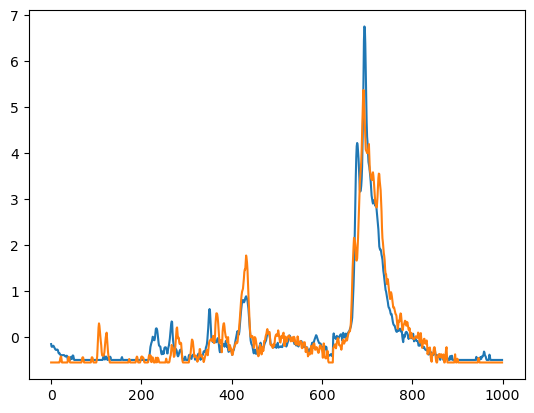

In [128]:
plt.plot(x_raman[360].T)
plt.plot((x - x.mean())/x.std())

In [132]:
id_ = 421
score_example = [score_list[0][id_:id_+1], score_list[1][id_:id_+1]] 
1-np.array(score_example).T

array([[[0.26234552, 0.4565239 ]],

       [[0.22132428, 0.50621179]],

       [[0.32298257, 0.48449259]],

       [[0.34542678, 0.46557087]],

       [[0.63636303, 0.47877623]],

       [[0.26412704, 0.49375626]]])

In [133]:
pd.DataFrame({'polymer':label_table['polymer'],
 'IR':1-smx_all_IR[421],
 'Raman':1-smx_all_Raman[421]})

,polymer,IR,Raman
0,NH2SO4,0.262346,0.456524
1,NaNO3,0.221324,0.506212
2,PE,0.322983,0.484493
3,PP,0.345427,0.465571
4,PSL,0.636363,0.478776
5,sucrose,0.264127,0.493756


(0.0, 1.0)

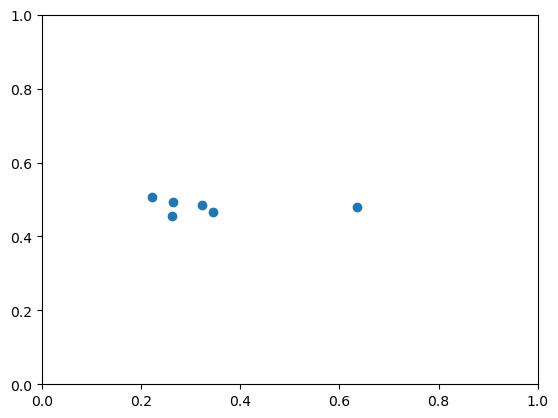

In [134]:
plt.scatter(1-smx_all_IR[421],
            1-smx_all_Raman[421])
plt.xlim(0,1)
plt.ylim(0,1)

In [81]:
Raman_spectra_all.query('id== "mix_446"')

,355.0,357.0,359.0,361.0,363.0,365.0,367.0,369.0,371.0,373.0,...,3489.0,3491.0,3493.0,3495.0,3497.0,3499.0,map_x,map_y,polymer,id
253,-0.444662,-0.444662,-0.444662,-0.444662,-0.444662,-0.444662,-0.444662,-0.444662,-0.444662,-0.444662,...,-0.444662,-0.444662,-0.444662,-0.444662,-0.444662,-0.444662,0,0,PP,mix_446


In [79]:
label_table

,label,polymer
0,0,NH2SO4
1,1,NaNO3
2,2,PE
3,3,PP
4,4,PSL
5,5,sucrose


In [69]:
np.sum(idx_raman),len(idx_raman)

(954, 1577)

In [ ]:
#Example ideal particle: Mix_301
#Example low-quality particle: Mix_607
#Example idea/augmented PTIR/augmented Raman particle: Mix_444

In [70]:
id_example = np.where(Raman_spectra_all['id'] == "mix_301")[0][0]
Raman_spectra_all.iloc[id_example:id_example+1, :]

,355.0,357.0,359.0,361.0,363.0,365.0,367.0,369.0,371.0,373.0,...,3489.0,3491.0,3493.0,3495.0,3497.0,3499.0,map_x,map_y,polymer,id
211,-0.299159,-0.302228,-0.307927,-0.314565,-0.32517,-0.334514,-0.341466,-0.345075,-0.34654,-0.332361,...,-0.459824,-0.459824,-0.459824,-0.459824,-0.459824,-0.459824,0,0,PSL,mix_301


In [71]:
quality[id_example]

'ideal'

In [62]:
1-smx_all_IR[id_example],1-smx_all_Raman[id_example]

(array([0.84502311, 0.85082018, 0.87099691, 0.90617256, 0.9034843 ,
        0.8515209 ]),
 array([0.83113077, 0.83364472, 0.88088435, 0.89000534, 0.9177627 ,
        0.87208123]))

In [72]:
1-smx_all_IR[id_example],1-smx_all_Raman[id_example]

(array([0.84502311, 0.85082018, 0.87099691, 0.90617256, 0.9034843 ,
        0.8515209 ]),
 array([0.82340743, 0.82629815, 0.87959679, 0.89189211, 0.91630604,
        0.8727562 ]))

In [73]:
label_table

,label,polymer
0,0,NH2SO4
1,1,NaNO3
2,2,PE
3,3,PP
4,4,PSL
5,5,sucrose


(0.8, 1.0)

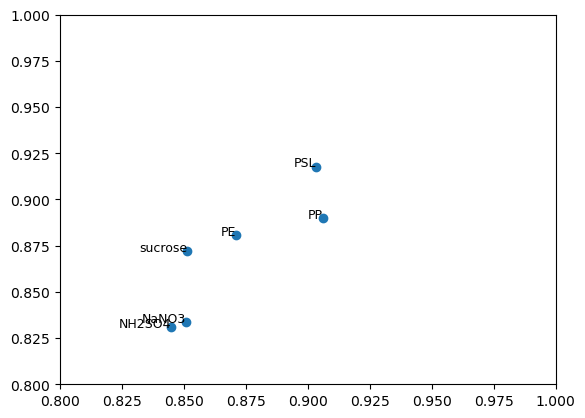

In [61]:
plt.scatter(
    1-smx_all_IR[id_example],
    1-smx_all_Raman[id_example]
)
for i in range(6):
        plt.text((1-smx_all_IR[id_example])[i], 
                 (1-smx_all_Raman[id_example])[i], label_table.iloc[i,1], fontsize=9, ha='right')
plt.xlim(0.8,1)
plt.ylim(0.8,1)


(0.8, 1.0)

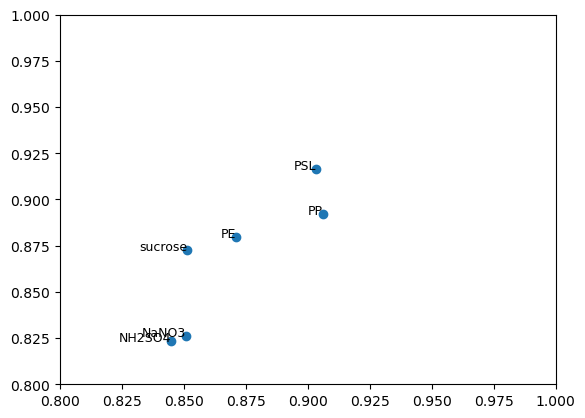

In [52]:
plt.scatter(
    1-smx_all_IR[id_example],
    1-smx_all_Raman[id_example]
)
for i in range(6):
        plt.text((1-smx_all_IR[id_example])[i], 
                 (1-smx_all_Raman[id_example])[i], label_table.iloc[i,1], fontsize=9, ha='right')
plt.xlim(0.8,1)
plt.ylim(0.8,1)


In [53]:
id_example = np.where(Raman_spectra_all['id'] == "mix_607")[0][0]
Raman_spectra_all.iloc[id_example:id_example+1, :]

,355.0,357.0,359.0,361.0,363.0,365.0,367.0,369.0,371.0,373.0,...,3489.0,3491.0,3493.0,3495.0,3497.0,3499.0,map_x,map_y,polymer,id
522,0.256267,0.266045,0.268568,0.268727,0.260519,0.222726,0.128772,0.150578,0.246638,0.227741,...,-0.693963,-0.693963,-0.693963,-0.693963,-0.693963,-0.693963,0,0,PSL,mix_607


In [54]:
quality[id_example]

'low_ir'

(0.8, 1.0)

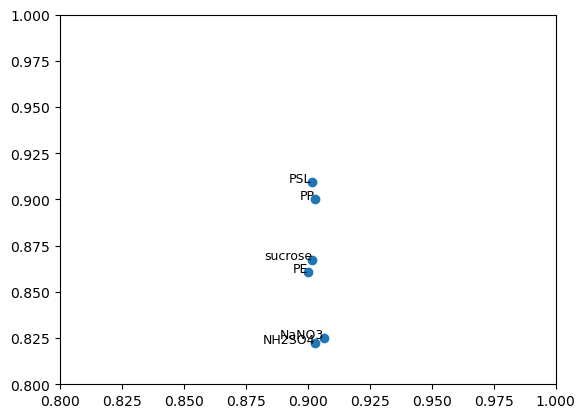

In [55]:
plt.scatter(
    1-smx_all_IR[id_example],
    1-smx_all_Raman[id_example]
)
for i in range(6):
        plt.text((1-smx_all_IR[id_example])[i], 
                 (1-smx_all_Raman[id_example])[i], label_table.iloc[i,1], fontsize=9, ha='right')
plt.xlim(0.8,1)
plt.ylim(0.8,1)


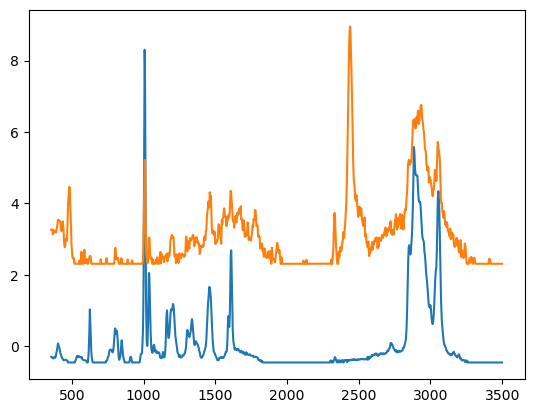

In [28]:
_ = plt.plot(Raman_spectra_all.query('id=="mix_301"').iloc[:,:-4].T)
_ = plt.plot(3+Raman_spectra_all.query('id=="mix_607"').iloc[:,:-4].T)

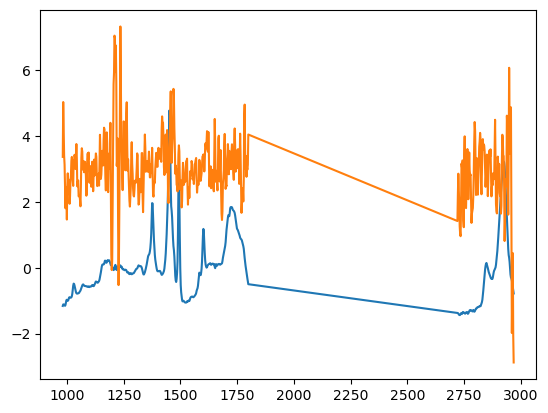

In [34]:
_ = plt.plot(IR_spectra_all.query('id=="mix_301"').iloc[:,:-8].T)
_ = plt.plot(3+IR_spectra_all.query('id=="mix_607"').iloc[:,:-8].T)

In [13]:
score_list[0].shape, label_ir.shape, quality.shape

((530, 6), (321,), (321,))

In [85]:
for p in ([.10, .20, .30, .50]):
    q = 1-.16/(1-p)
    print(p, q*(1-p), 530*(1-p)*(1-q))
    
    p1, p2 = round(p/(p+q*(1-p)),2), round(q*(1-p)/(p+q*(1-p)), 2)
    print(p1, p2 )
    

0.1 0.74 84.80000000000001
0.12 0.88
0.2 0.6400000000000001 84.79999999999998
0.24 0.76
0.3 0.5399999999999999 84.80000000000003
0.36 0.64
0.5 0.33999999999999997 84.80000000000001
0.6 0.4


In [60]:
score_list[0].shape

(530, 6)

In [70]:
df_res_all_lis[0]['mvcp'][0].shape

(85,)

In [73]:
.8*.2

0.16000000000000003

In [81]:
#alphas = [0.05]
alphas = np.arange(0,.2,.01)
N_sim = 2
set_size_df = []
set_size_std_df = []
cov_df = []
cov_std_df = []

#for N in tqdm([10, 20, 30, 50, 100, 200, 400]):
for p in tqdm([.10, .20, .30, .50, .80]):
    N = 20
    p2 = 1-.16/(1-p)
    (df_res_lis, 
         df_res_sd_lis, 
         df_res_cov_lis, 
         df_res_cov_sd_lis, 
         df_res_all_mean_lis, 
         df_res_cov_all_mean_lis,
         df_res_all_lis, 
         df_res_cov_all_lis,
         df_res_labels_all,
         df_res_pred_set_all_lis)  = experiment_fig_1_2(score_list,                                      
                                       label_ir,                                   
                                       #quality,
                                       alphas=alphas,
                                       N_sim=N_sim, 
                                       quant_prop=p, 
                                       cal_prop=p2, 
                                       seed_init=0,
                                       n_th=N)
    set_size_df.append(pd.concat(df_res_lis, axis=0).loc[:,['mvcp']].rename({'mvcp':'mvcp_'+str(p)},axis=1))
    set_size_std_df.append(pd.concat(df_res_sd_lis, axis=0).loc[:,['mvcp']].rename({'mvcp':'mvcp_'+str(p)},axis=1))
    cov_df.append(pd.concat(df_res_cov_lis, axis=0).loc[:,['mvcp']].rename({'mvcp':'mvcp_'+str(p)},axis=1))
    cov_std_df.append(pd.concat(df_res_cov_sd_lis, axis=0).loc[:,['mvcp']].rename({'mvcp':'mvcp_'+str(p)},axis=1))

    #df_res_all = pd.concat(df_res_lis, axis=0)
    #df_res_all['confidence'] = (1-np.array(alphas))*100
    #df_list.append(df_res_all)
    #_ = plt.plot(np.round(df_res_all, 2).set_index('confidence'))
    #_ = plt.legend(['view_IR', 'view_Raman', 'mvcp'])
    #_ = plt.xlabel("Confidence")
    #_ = plt.ylabel("Prediction Sets Size")
    #_ = plt.show()
    

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:02<00:00,  2.39it/s]


In [82]:

set_size_df_all = pd.concat(set_size_df, axis=1)
set_size_df_all['confidence'] = (1-np.array(alphas))*100

set_size_std_df_all = pd.concat(set_size_std_df, axis=1)
set_size_std_df_all['confidence'] = (1-np.array(alphas))*100

cov_df_all = pd.concat(cov_df, axis=1)
cov_df_all['confidence'] = (1-np.array(alphas))*100

cov_std_df_all = pd.concat(cov_std_df, axis=1)
cov_std_df_all['confidence'] = (1-np.array(alphas))*100


set_size_df_all = set_size_df_all.set_index('confidence')
set_size_std_df_all = set_size_std_df_all.set_index('confidence')
cov_df_all = cov_df_all.set_index('confidence')
cov_std_df_all = cov_std_df_all.set_index('confidence')


In [84]:
set_size_df_all

index,mvcp_0.1,mvcp_0.2,mvcp_0.3,mvcp_0.5,mvcp_0.8
confidence,,,,,
100.0,3.794118,3.764706,3.547059,4.147059,1.347059
99.0,3.223529,3.705882,3.547059,4.147059,1.164706
98.0,2.205882,2.041176,2.323529,2.364706,1.276471
97.0,1.723529,1.311765,1.376471,1.752941,1.329412
96.0,1.294118,1.147059,1.188235,1.305882,1.429412
95.0,1.135294,1.035294,1.129412,1.211765,1.452941
94.0,1.047059,1.011765,1.058824,1.141176,1.458824
93.0,1.047059,0.976471,1.017647,1.035294,1.541176
92.0,0.982353,0.952941,0.982353,1.005882,1.452941


In [23]:
df_all = pd.concat([x.loc[:,['mvcp','confidence']].set_index('confidence') for x in df_list], axis=1)
df_all.columns = ['mvcp_'+str(x) for x in [10, 20, 30, 50, 100, 200, 400]]
df_all

,mvcp_10,mvcp_20,mvcp_30,mvcp_50,mvcp_100,mvcp_200,mvcp_400
confidence,,,,,,,
100.0,3.912941,3.888235,3.930588,4.017647,4.050588,4.063529,4.064706
99.0,3.352941,3.374118,3.387059,3.462353,3.518824,3.537647,3.537647
98.0,2.072941,2.065882,2.060000,2.092941,2.111765,2.131765,2.129412
97.0,1.329412,1.325882,1.341176,1.354118,1.354118,1.355294,1.352941
96.0,1.188235,1.171765,1.181176,1.224706,1.224706,1.223529,1.221176
95.0,1.071765,1.069412,1.067059,1.076471,1.082353,1.081176,1.078824
94.0,1.032941,1.029412,1.025882,1.032941,1.032941,1.031765,1.029412
93.0,0.996471,0.997647,0.996471,1.002353,1.003529,1.002353,1.002353
92.0,0.971765,0.971765,0.970588,0.969412,0.967059,0.967059,0.967059


<AxesSubplot: xlabel='confidence'>

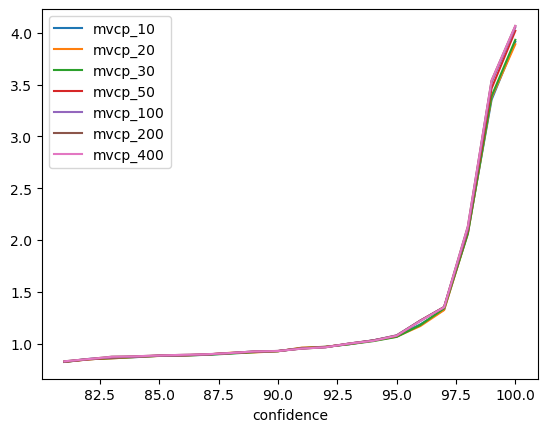

In [24]:
df_all.plot()

In [56]:


df_res_all = pd.concat([pd.concat(df_res_lis, axis=0), pd.concat(df_res_sd_lis, axis=0)],axis=1)
df_res_all.columns = ["set size "+x +" (mean)" for x in df_res_all.columns[:3]] + ["set size "+x+" (standard deviation)" for x in df_res_all.columns[3:]]
df_res_all['confidence'] = (1-alphas)*100
df_res_all

,set size view_IR (mean),set size view_Raman (mean),set size mvcp (mean),set size view_IR (standard deviation),set size view_Raman (standard deviation),set size mvcp (standard deviation),confidence
0,5.070588,4.441176,4.064706,0.412194,0.668124,0.719611,100.0
0,4.397647,3.322353,3.537647,0.634756,0.468630,0.798616,99.0
0,3.057647,1.905882,2.129412,0.370103,0.212055,0.669751,98.0
0,2.215294,1.554118,1.352941,0.301224,0.211943,0.225618,97.0
0,1.950588,1.400000,1.221176,0.192820,0.110084,0.130630,96.0
0,1.810588,1.294118,1.078824,0.188435,0.090621,0.074417,95.0
0,1.740000,1.240000,1.029412,0.186301,0.078471,0.057166,94.0
0,1.672941,1.194118,1.002353,0.166913,0.062315,0.059680,93.0
0,1.575294,1.141176,0.967059,0.163530,0.051131,0.046001,92.0
0,1.496471,1.117647,0.954118,0.184255,0.045395,0.050965,91.0


In [47]:
np.arange(10, 450, 50)
[10, 20, 30, 50, 100, 200, 400]

array([ 10,  60, 110, 160, 210, 260, 310, 360, 410])

In [3]:
id_ = 519#116
example_id = IR_spectra_all.iloc[id_,-2]
score_example = [score_list[0][id_:id_+1], score_list[1][id_:id_+1]]
env_directions_list = []
n_dir = np.array([10, 20, 30, 50, 100, 200, 400])

for N in n_dir:
    (ps_list, 
     ps_ir_list, 
     ps_raman_list, 
     env_list, 
     cal_smx_arr, 
     cal_idx_list, 
     q_ir_list, 
     q_raman_list, 
     beta_list) = envelop(score_list, label_ir, score_example,
                             alphas=[0.05],
                             label_table=label_table,
                             N_sim=1, 
                             quant_prop=.2, 
                             cal_prop=0.8, 
                             seed_init=0,
                             cp=False,
                            plot=False,
                             n_th=N)
    env_directions_list.append(np.array(env_list[5][0]).T)

100%|█████████████████████████████████████████████| 1/1 [00:00<00:00, 10.36it/s]


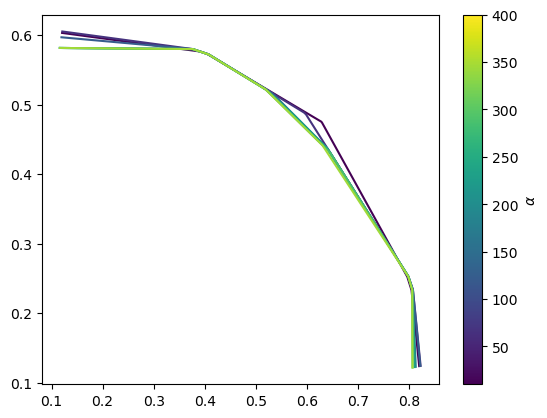

In [4]:
#for e in env_directions_list:
#    plt.plot(e[:,0], e[:,1])
    
    
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.cm import get_cmap


norm = Normalize(vmin=min(n_dir), vmax=max(n_dir))
#cmap = plt.cm.viridis
# Choose a colormap (e.g., 'viridis', 'plasma', 'coolwarm', etc.)
cmap = get_cmap('viridis')

# Generate colors evenly spaced across the colormap
K = n_dir.shape[0]
#N = results['err'].shape[0]
colors = [cmap(i / K) for i in range(K)]

for j, e in enumerate(env_directions_list):#np.arange(0,results['q'].shape[0],100):
    
    plt.plot(
        e[:,0], e[:,1],
        color=colors[j]
    )
    
#plt.colorbar(scatter, label='Value of the Third Variable')

sm = ScalarMappable(norm=norm, cmap=cmap)
#sm.set_array([])  # required for older Matplotlib versions
plt.colorbar(sm, label=r'$\alpha$',ax=None,)

plt.show()

In [11]:
score_list_quant_projected = project_u_mv(score_list_quant, 
                                          U_list[0][l])[0][np.arange(label_list_quant.shape[0]),
                                                           label_list_quant]
score_list_quant_projected

array([0.27994891, 0.32524861, 0.12183672, 0.29761883, 0.3874473 ,
       0.15048073, 0.15271339, 0.13675305, 0.17413661, 0.14094019,
       0.0770759 , 0.16384697, 0.1601594 , 0.23029304, 0.07026864,
       0.22992667, 0.16975973, 0.06309665, 0.08989017, 0.28500899,
       0.23467584, 0.10010658, 0.0946148 , 0.16711537, 0.15109805,
       0.17153099, 0.49568294, 0.43637513, 0.35080485, 0.33984667,
       0.47570658, 0.32196754, 0.19332673, 0.43367928, 0.53789791,
       0.61979306, 0.62763461, 0.27851876, 0.26571072, 0.27306658,
       0.48211869, 0.27384719, 0.36552101, 0.28556563, 0.51877179,
       0.32692158, 0.30576659, 0.25897984, 0.34963116, 0.52507976,
       0.63411338, 0.71055838, 0.34815104, 0.18191777, 0.25373051,
       0.42227176, 0.29944316, 0.29136731, 0.4884242 , 0.32069919,
       0.46986952, 0.37759405, 0.29979736, 0.43379562, 0.3063002 ,
       0.20168957, 0.20499262, 0.45597728, 0.25366596, 0.2052045 ,
       0.18859729, 0.50061784, 0.23361262, 0.50913714, 0.21377

In [47]:
env_th = np.array(env_list[5][0]).T #@ u_theta
directions = np.where(
    np.array([np.max([np.sum(np.abs((env_th - env_th[i])@ U_list[0][l][:,None])<1e-12) for i in range(env_th.shape[0])]) for l in range(400)])>1
)[0]

directions

array([ 13,  48, 118, 141, 180, 317])

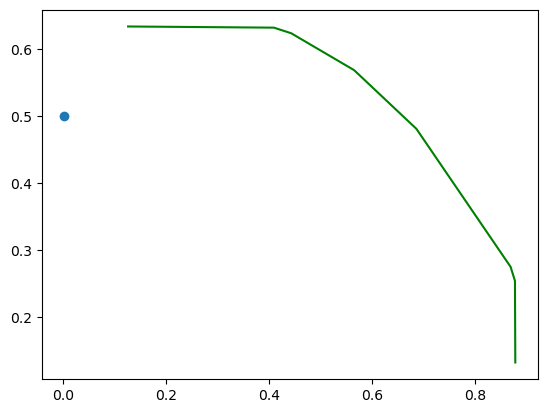

In [32]:
plt.plot(env_list[5][0][0]/t_list[5][0][1], 
         env_list[5][0][1]/t_list[5][0][1], color='green', label='raw')
plt.scatter(u_theta[0]/2, u_theta[1]/2)
#plt.xlim(-.01,1.01)
#plt.ylim(-.01,1.01)

(0.0, 1.0)

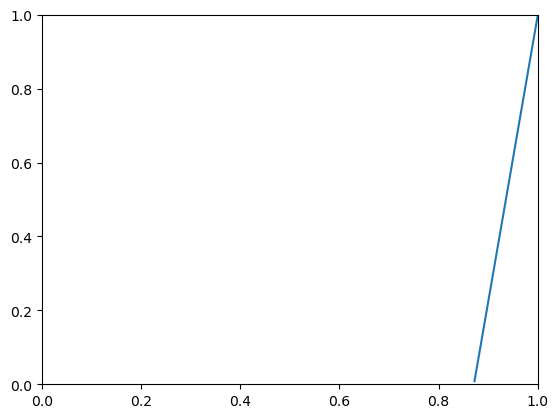

In [95]:
plt.plot([1,1-U_list[0][294][0]],
           [1,1-U_list[0][294][1]])
plt.xlim(0,1)
plt.ylim(0,1)

In [94]:
np.argsort(U_list[0] @ np.array([0,1]))[::-1]#[50]

array([ 48, 373, 344, 284, 377, 333, 192, 379, 103,  96,  75, 108, 286,
       328,  27, 320, 303, 398, 163, 182,   5, 187, 369, 140, 281, 313,
       352, 289, 147, 325, 155, 294, 135, 158,  77, 271, 259, 148, 227,
       151, 270, 349, 122, 388, 296, 387, 244, 232, 228,  46, 196,  28,
        61, 204, 342, 189,  63, 184, 260,  13, 285,   4,  90,  80,  71,
       376, 262, 185,  91, 335,  41, 304, 312, 161,  49, 242, 307, 215,
        45,  57, 220,  60, 213, 345,  69,   9, 197, 324, 236,  92, 329,
       102, 188,  15, 169, 273,  26, 348,   1, 368,  32, 221, 126, 121,
        16, 141,  56, 391, 375, 142,  31, 223, 258, 361,  94, 366, 183,
       293, 347, 327,  47, 399, 277, 128, 340, 230, 144, 175, 200,  53,
       124, 337, 171, 159, 283,  37, 252, 319,  52, 326, 365, 165, 119,
        83, 255, 382, 166, 263,  59, 193, 113, 306, 256, 308, 396, 332,
       288, 351, 118,  20, 330, 311, 164, 240, 363, 198, 360, 179,  42,
       150,  73, 346, 246, 309, 143, 272, 341,  21, 209, 160,  7

In [107]:
U_list[0][directions]

array([[0.0058794 , 0.99998272],
       [0.23746516, 0.97139606],
       [0.41070033, 0.91177039],
       [0.58536065, 0.81077304],
       [0.74750487, 0.66425633],
       [0.99998543, 0.00539881]])

100%|█████████████████████████████████████████████| 5/5 [00:01<00:00,  3.39it/s]


50 0.6788274980003052
50 0.7108323124111223


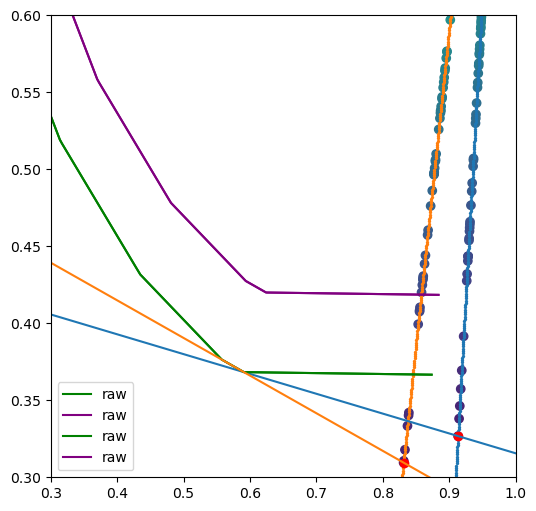

In [171]:

for n_th in [400]:#[4, 5, 6, 20, 400]:
    (ps_list, 
     ps_ir_list, 
     ps_raman_list, 
     env_list, 
     cal_smx_arr, 
     cal_idx_list, 
     q_ir_list, 
     q_raman_list,
     beta_list,
     t_list,
     q_array_list) = envelop_3(score_list, label_ir, score_example,
                             alphas=[0.40,.20, .10, 0.05, 0.02],
                             label_table=label_table,
                             N_sim=1, 
                             quant_prop=.2, 
                             cal_prop=0.8, 
                             seed_init=0,
                            n_th=n_th)

    K = 2
    U_list = gen_u(K, n_th=n_th, seed=0)

    idx_quant = cal_idx_list[20][0][0]
    idx = cal_idx_list[20][0][1]

    score_list_cal = [score_list[0][~idx_quant][idx],
                      score_list[1][~idx_quant][idx]]
    label_list_cal = label_ir[~idx_quant][idx]

    score_list_quant = [score_list[0][idx_quant],
                      score_list[1][idx_quant]]
    label_list_quant = label_ir[idx_quant]

    quant_smx_arr = np.array(score_list_quant)[:,
                             np.arange(label_list_quant.shape[0]),                           
                             label_list_quant]
    
    df_projections = pd.DataFrame()
    df_orth_list = [] 
    df_orth = pd.DataFrame()
    env_th = np.array(env_list[5][0]).T #@ u_theta
    directions = np.where(
            np.array([np.max([np.sum(np.abs((env_th - env_th[i])@ U_list[0][l][:,None])<1e-12) for i in range(env_th.shape[0])]) for l in range(n_th)])>1
        )[0]
    directions = np.concatenate([directions, [294]])
    directions = directions[np.argsort(U_list[0][directions] @ np.array([1,0]))]
    plt.figure(figsize=(6, 6))


    for l in directions[1:3]:#[180, 350, 150, 48]: #233 #75, 96
        #print(l)

        plt.plot(1-env_list[5][0][0]/t_list[5][0][1], 
                 1-env_list[5][0][1]/t_list[5][0][1], color='green', label='raw')
        
        plt.plot(1-env_list[5][0][0], 
                 1-env_list[5][0][1], color='purple', label='raw')

        score_list_quant_projected = project_u_mv(score_list_quant, U_list[0][l])[0][np.arange(label_list_quant.shape[0]),
                                                        label_list_quant]

        u_theta = U_list[0][l][:,None]
        score_list_quant_projected_vect = (u_theta*score_list_quant_projected).T

        n = score_list_quant_projected.shape[0]
        beta = beta_list[5][0]
        q_level = np.clip(np.ceil((n+1)*(1-beta))/n, 0, 1)
        quant_proj = np.quantile(score_list_quant_projected, q_level, method='higher')

        id_point = np.where(score_list_quant_projected == quant_proj)[0][0]
        print(id_point, quant_proj)
        #plt.figure(figsize=(6, 6))

        #plt.scatter(1-quant_smx_arr[0,:],
        #            1-quant_smx_arr[1,:], alpha=.2)
        #plt.scatter(1-u_theta[0],
        #            1-u_theta[1])

        plt.scatter(1-score_list_quant_projected_vect[:,0],
                    1-score_list_quant_projected_vect[:,1],
                    c=np.linalg.norm(1-score_list_quant_projected_vect, axis=1)/np.sqrt(2))

        plt.scatter(1-u_theta[0]*np.linspace(0,1.5,1000),
                    1-u_theta[1]*np.linspace(0,1.5,1000),
                    s=2)

        plt.scatter(1-score_list_quant_projected_vect[id_point,0],
                    1-score_list_quant_projected_vect[id_point,1],
                    color='red')

        orth_vect = np.array([score_list_quant_projected_vect[id_point,0],
        score_list_quant_projected_vect[id_point,1]])[:,None] + (np.concatenate([-u_theta[1],u_theta[0]])[:,None]*np.linspace(-1,1, 100))


        plt.plot(1-orth_vect[0,:],
                    1-orth_vect[1,:], 
                 #color='orange'
                # s=1
                )

        df_aux = pd.DataFrame(1-score_list_quant_projected_vect)
        df_aux.columns = ['IR - '+str(l), 'Raman - '+str(l)]
        df_aux['threshold_'+str(l)] = 0
        df_aux.iloc[id_point,2] = 1
        df_projections = pd.concat([df_projections, df_aux], axis=1)

        df_aux = pd.DataFrame(1-orth_vect.T)
        df_aux.columns = ['IR', 'Raman']
        df_aux = df_aux.query('IR>0 and IR < 1 and Raman >0 and Raman < 1').reset_index(drop=True)
        df_aux.columns = ['IR - '+str(l), 'Raman - '+str(l)]
        df_orth_list.append(df_aux)
        #df_orth = pd.concat([df_orth, df_aux], axis=1)

        #plt.xlim(-.01,1.01)
        #plt.ylim(-.01,1.01)
        plt.xlim(.3,1)
        plt.ylim(.3,.6)
        #plt.show()

    plt.legend()
    plt.show()

In [170]:
df_projections

,IR - 294,Raman - 294,threshold_294,IR - 13,Raman - 13,threshold_13
0,0.960424,0.692768,0,0.920929,0.676544,0
1,0.952851,0.633978,0,0.904004,0.607309,0
2,0.983153,0.869217,0,0.966919,0.864678,0
3,0.956239,0.660280,0,0.909978,0.631749,0
4,0.948319,0.598794,0,0.901488,0.597019,0
...,...,...,...,...,...,...
101,0.945319,0.575507,0,0.887114,0.538218,0
102,0.942845,0.556302,0,0.879296,0.506237,0
103,0.945193,0.574533,0,0.885873,0.533141,0
104,0.939853,0.533078,0,0.877088,0.497205,0


In [169]:
pd.concat(df_orth_list, axis=1)

,IR - 294,Raman - 294,IR - 13,Raman - 13
0,0.001614,0.444171,0.016799,0.508587
1,0.021651,0.441590,0.036423,0.503790
2,0.041687,0.439009,0.056048,0.498993
3,0.061723,0.436428,0.075672,0.494195
4,0.081760,0.433847,0.095296,0.489398
5,0.101796,0.431266,0.114920,0.484601
6,0.121833,0.428685,0.134544,0.479804
7,0.141869,0.426104,0.154168,0.475006
8,0.161906,0.423523,0.173793,0.470209
9,0.181942,0.420942,0.193417,0.465412


100%|████████████████████████████████████████████| 5/5 [00:00<00:00, 209.08it/s]


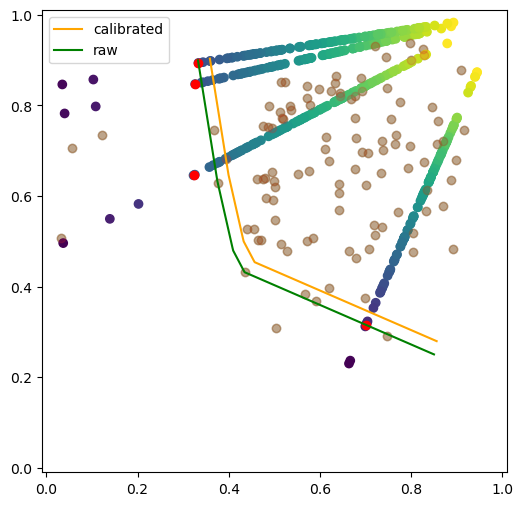

100%|████████████████████████████████████████████| 5/5 [00:00<00:00, 249.12it/s]


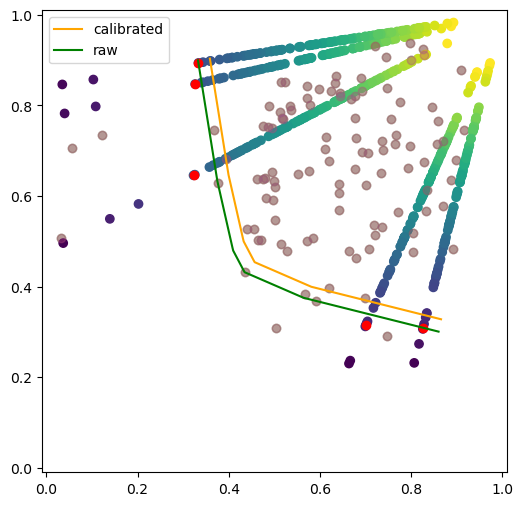

100%|████████████████████████████████████████████| 5/5 [00:00<00:00, 197.54it/s]


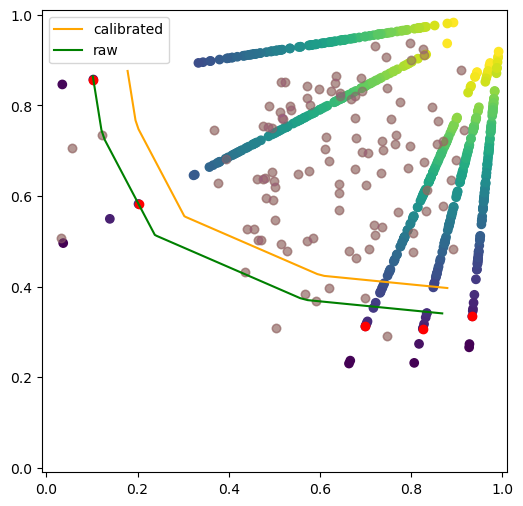

100%|█████████████████████████████████████████████| 5/5 [00:00<00:00, 80.41it/s]


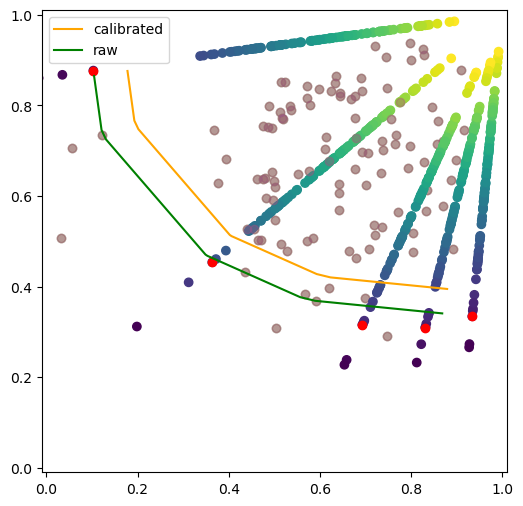

100%|█████████████████████████████████████████████| 5/5 [00:01<00:00,  3.76it/s]


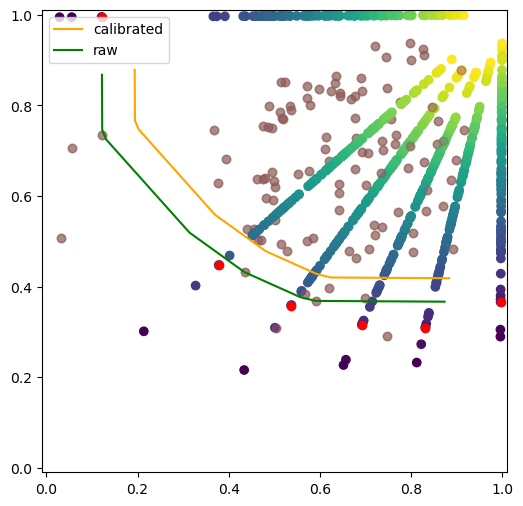

In [67]:
id_ = 421
score_example = [score_list[0][id_:id_+1], score_list[1][id_:id_+1]] 

for n_th in [4, 5, 6, 20, 400]:
    (ps_list, 
     ps_ir_list, 
     ps_raman_list, 
     env_list, 
     cal_smx_arr, 
     cal_idx_list, 
     q_ir_list, 
     q_raman_list,
     beta_list,
     t_list,
     q_array_list) = envelop_3(score_list, label_ir, score_example,
                             alphas=[0.40,.20, .10, 0.05, 0.02],
                             label_table=label_table,
                             N_sim=1, 
                             quant_prop=.2, 
                             cal_prop=0.8, 
                             seed_init=0,
                            n_th=n_th)

    K = 2
    U_list = gen_u(K, n_th=n_th, seed=0)

    idx_quant = cal_idx_list[20][0][0]
    idx = cal_idx_list[20][0][1]

    score_list_cal = [score_list[0][~idx_quant][idx],
                      score_list[1][~idx_quant][idx]]
    label_list_cal = label_ir[~idx_quant][idx]

    score_list_quant = [score_list[0][idx_quant],
                      score_list[1][idx_quant]]
    label_list_quant = label_ir[idx_quant]

    quant_smx_arr = np.array(score_list_quant)[:,
                             np.arange(label_list_quant.shape[0]),                           
                             label_list_quant]

    plt.figure(figsize=(6, 6))
    plt.plot(1-env_list[5][0][0], 
             1-env_list[5][0][1], color='orange', label='calibrated')
    plt.plot(1-env_list[5][0][0]/t_list[5][0][1], 
             1-env_list[5][0][1]/t_list[5][0][1], color='green', label='raw')

    plt.legend()
    df = pd.DataFrame()
    env_th = np.array(env_list[5][0]).T #@ u_theta
    directions = np.where(
        np.array([np.max([np.sum(np.abs((env_th - env_th[i])@ U_list[0][l][:,None])<1e-12) for i in range(env_th.shape[0])]) for l in range(n_th)])>1
    )[0]


    for l in directions:#[180, 350, 150, 48]: #233 #75, 96
        #print(l)
        score_list_quant_projected = project_u_mv(score_list_quant, U_list[0][l])[0][np.arange(label_list_quant.shape[0]),
                                                        label_list_quant]

        u_theta = U_list[0][l][:,None]
        score_list_quant_projected_vect = (u_theta*score_list_quant_projected).T

        n = score_list_quant_projected.shape[0]
        beta = beta_list[5][0]
        q_level = np.clip(np.ceil((n+1)*(1-beta))/n, 0, 1)
        quant_proj = np.quantile(score_list_quant_projected, q_level, method='higher')

        id_point = np.where(score_list_quant_projected == quant_proj)[0][0]


        #plt.figure(figsize=(6, 6))

        plt.scatter(1-quant_smx_arr[0,:],
                    1-quant_smx_arr[1,:], alpha=.2)
        #plt.scatter(1-u_theta[0],
        #            1-u_theta[1])

        plt.scatter(1-score_list_quant_projected_vect[:,0],
                    1-score_list_quant_projected_vect[:,1],
                    c=np.linalg.norm(1-score_list_quant_projected_vect, axis=1)/np.sqrt(2))

        plt.scatter(1-score_list_quant_projected_vect[id_point,0],
                    1-score_list_quant_projected_vect[id_point,1],
                    color='red')

        df_aux = pd.DataFrame(1-score_list_quant_projected_vect)
        df_aux.columns = ['IR - '+str(l), 'Raman - '+str(l)]
        df_aux['threshold - '+str(l)] = 0
        df_aux.iloc[id_point,2] = 1
        df = pd.concat([df, df_aux], axis=1)

        plt.xlim(-.01,1.01)
        plt.ylim(-.01,1.01)
    plt.show()

In [181]:
# Figure 1

id_ = 519#116
example_id = IR_spectra_all.iloc[id_,-2]
score_example = [score_list[0][id_:id_+1], score_list[1][id_:id_+1]]

(ps_list, 
 ps_ir_list, 
 ps_raman_list, 
 env_list, 
 cal_smx_arr, 
 cal_idx_list, 
 q_ir_list, 
 q_raman_list,
 beta_list,
 t_list,
 q_array_list) = envelop_3(score_list, label_ir, score_example,
                         alphas=[0.40,.20, .10, 0.05, 0.02],
                         label_table=label_table,
                         N_sim=1, 
                         quant_prop=.2, 
                         cal_prop=0.8, 
                         seed_init=0)

100%|█████████████████████████████████████████████| 5/5 [00:01<00:00,  3.57it/s]


In [180]:
t_list[5][0][1]

0.9181731171391925

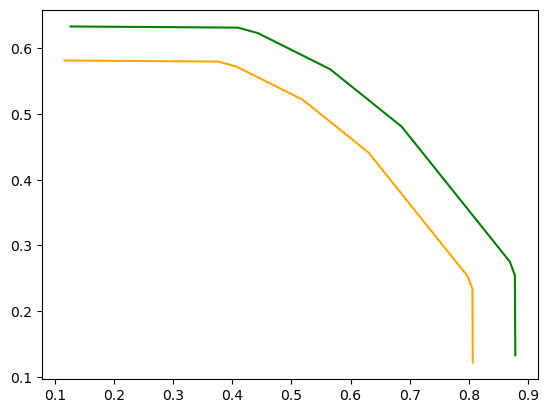

In [177]:
plt.plot(env_list[5][0][0], 
         env_list[5][0][1], color='orange', label='calibrated')
plt.plot(env_list[5][0][0]/t_list[5][0][1], 
         env_list[5][0][1]/t_list[5][0][1], color='green', label='raw')


180
233
350
150
48


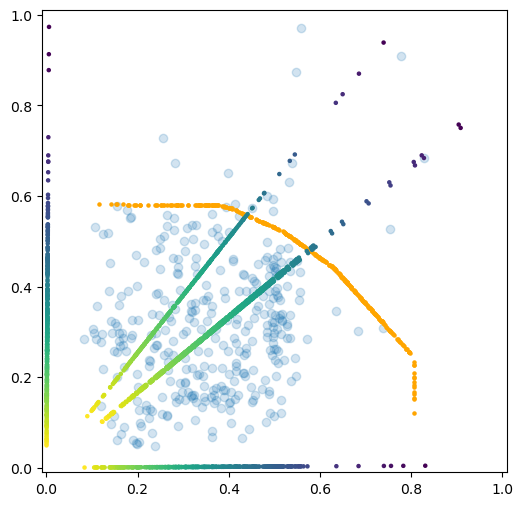

In [10]:
plt.figure(figsize=(6, 6))

plt.scatter(cal_smx_arr[0,:],
                cal_smx_arr[1,:], alpha=.2)
    
plt.scatter(env_list[5][0][0], 
     env_list[5][0][1], color='orange', s=5)

for l in [180, 233, 350, 150, 48]: #75, 96
    print(l)
    score_list_cal_projected = project_u_mv(score_list_cal, U_list[0][l])[0][np.arange(label_list_cal.shape[0]),
                                                    label_list_cal]

    u_theta = U_list[0][l][:,None]
    score_list_cal_projected_vect = (u_theta*score_list_cal_projected).T

    #plt.scatter(1-u_theta[0],
    #            1-u_theta[1])

    plt.scatter(score_list_cal_projected_vect[:,0],
                score_list_cal_projected_vect[:,1],
                c=np.linalg.norm(1-score_list_cal_projected_vect, axis=1)/np.sqrt(2), s=5)

    

    
    
    #plt.scatter(1-score_list_cal_projected_vect[4,0],
    #            1-score_list_cal_projected_vect[4,1],
    #            c='r')

    plt.xlim(-.01,1.01)
    plt.ylim(-.01,1.01)
    #plt.show()

In [12]:
np.argmin(np.abs(np.arccos(U_list[0])[:,0] - np.pi/6))

358

In [13]:
np.where(np.logical_and(score_list_cal_projected>0.70305233,
                        score_list_cal_projected<0.72305233))[0]

array([], dtype=int64)

In [14]:
np.argsort(score_list_cal_projected)

array([ 42,  23,  44,  28,  82,   2, 215,  21,   6,  40,   8, 237,  64,
         0,  69,  68,  73,  70, 216,  90,  66,   3,  79, 230,  10,  67,
        35,  85,  65,  14,  89, 229,  77,  39,  36,  24,  63,  29, 116,
        31,  60, 218,  13,  33,  62, 222,  53, 236,  26,  57,   4,  38,
        47,  46,   7,  54,   5,  50,  59,  30, 224,  88,  94, 223,  27,
       219,  58, 283,  52,  61, 217,  75,  43, 196, 258,  17, 238,  49,
       179, 114, 200,  92, 177, 257, 141,  11,  86, 253,  22, 134,  95,
         1,  76, 249, 248,  84, 109, 123,  32, 130,  48,  83, 232, 178,
       142,  81, 115, 194,  41, 161, 203, 314, 256, 234, 103, 104,  45,
       137, 166, 252,  25, 198, 127,  91, 170,  99, 143, 176, 335, 226,
       308, 262, 220, 106, 208, 136, 111, 139, 131, 189, 171, 320, 211,
       205, 186, 326, 126, 190,  18, 100, 210,  71,  37, 270, 272, 317,
       255, 187, 128, 140, 173, 197, 188,  20, 149, 172, 336, 227, 318,
       156, 292, 175, 310, 180, 309, 163, 243, 153, 277, 174, 26

In [15]:
np.array([u*q_array_list[5][0][i] for i, u in enumerate(U_list[0])])

array([[0.89184508, 0.20230592],
       [0.30047842, 0.68796763],
       [0.79795509, 0.4175634 ],
       [0.89703629, 0.14290555],
       [0.17431905, 0.6934309 ],
       [0.06593885, 0.66572307],
       [0.89702471, 0.14341667],
       [0.6882071 , 0.51735991],
       [0.89704749, 0.12317735],
       [0.25899222, 0.7065697 ],
       [0.88732435, 0.22717352],
       [0.63639757, 0.54638158],
       [0.74271813, 0.47590332],
       [0.16879791, 0.6904997 ],
       [0.60470863, 0.57968814],
       [0.28501739, 0.69560945],
       [0.30682239, 0.68457137],
       [0.82934808, 0.37270247],
       [0.600134  , 0.58651914],
       [0.67411917, 0.52613986],
       [0.47311005, 0.6407161 ],
       [0.55428376, 0.63371155],
       [0.63592072, 0.54660911],
       [0.75248549, 0.46699583],
       [0.89691708, 0.11822953],
       [0.83614341, 0.36127086],
       [0.29816997, 0.68916507],
       [0.04314897, 0.65580619],
       [0.15139299, 0.68842511],
       [0.77569269, 0.44358485],
       [0.

In [64]:
env_directions_df = pd.DataFrame(np.concatenate(env_directions_list, 1))
env_directions_df.columns = ['x_'+str(n_dir[i//2]) if i%2 == 0 else 'y_'+str(n_dir[i//2]) for i in range(14)]
env_directions_df

,x_10,y_10,x_20,y_20,x_30,y_30,x_50,y_50,x_100,y_100,x_200,y_200,x_400,y_400
0,0.120570,0.603197,0.120983,0.605263,0.119312,0.596900,0.116244,0.581552,0.116244,0.581552,0.116244,0.581552,0.116244,0.581552
1,0.145389,0.600739,0.145887,0.602796,0.144066,0.595271,0.140711,0.581409,0.140711,0.581409,0.140711,0.581409,0.140711,0.581409
2,0.156965,0.599592,0.157503,0.601645,0.155635,0.594510,0.152187,0.581341,0.152187,0.581341,0.152187,0.581341,0.152187,0.581341
3,0.160221,0.599270,0.160770,0.601322,0.158891,0.594296,0.155422,0.581322,0.155422,0.581322,0.155422,0.581322,0.155422,0.581322
4,0.173129,0.597991,0.173722,0.600039,0.171813,0.593446,0.168281,0.581247,0.168281,0.581247,0.168281,0.581247,0.168281,0.581247
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
334,0.813003,0.169743,0.815787,0.170324,0.815394,0.170242,0.809971,0.169110,0.808572,0.168818,0.806101,0.168302,0.806101,0.168302
335,0.813766,0.164189,0.816552,0.164751,0.816129,0.164665,0.810293,0.163488,0.808788,0.163184,0.806132,0.162648,0.806132,0.162648
336,0.814795,0.156690,0.817585,0.157226,0.817121,0.157137,0.810727,0.155907,0.809079,0.155590,0.806173,0.155032,0.806173,0.155032
337,0.815108,0.154412,0.817899,0.154940,0.817423,0.154850,0.810859,0.153607,0.809168,0.153286,0.806185,0.152721,0.806185,0.152721


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:09<00:00,  9.85s/it]


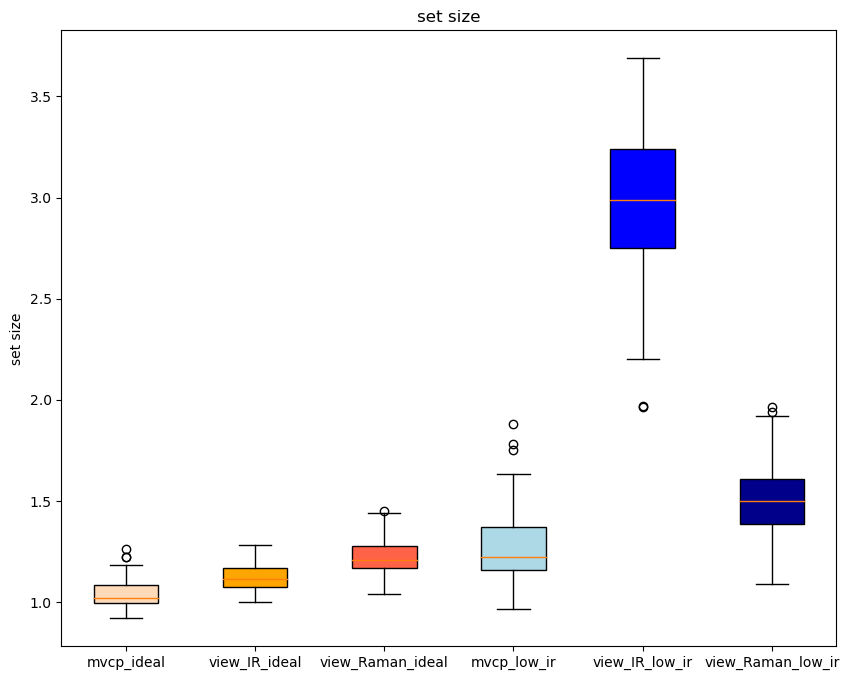

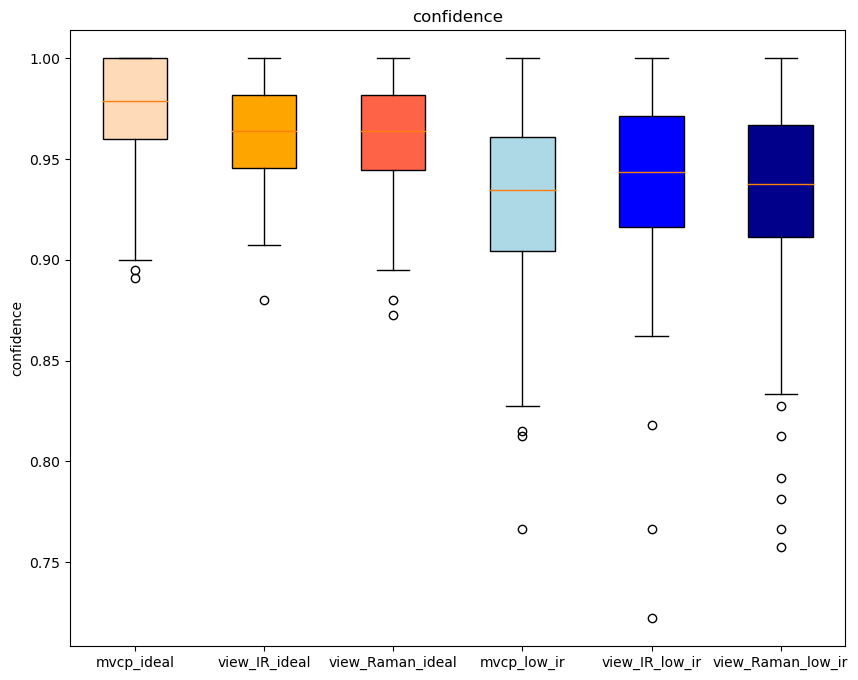

In [223]:
#Figure 3a real low quality

alphas = [0.05]
#alphas = np.arange(0,.2,.01)
N_sim = 100

(df_res_lis, 
 df_res_sd_lis,
 df_res_cov_lis, 
 df_res_cov_sd_lis, 
 df_res_all_mean_lis, 
 df_res_cov_all_mean_lis, 
 df_res_all_lis, 
 df_res_cov_all_lis)  = experiment_fig_3(score_list,                                      
                                   label_ir,                                   
                                   quality,
                                   alphas=alphas,
                                   N_sim=N_sim, 
                                   quant_prop=.2, 
                                   cal_prop=0.8, 
                                   seed_init=0)

                                   
labels = ['mvcp_ideal', 
          'view_IR_ideal', 
          'view_Raman_ideal', 
          'mvcp_low_ir', 
          'view_IR_low_ir', 
          'view_Raman_low_ir']

set_size = [np.array(df_res_all_mean_lis[0][x]) for x in labels]#df_res_all_lis[0]
#emp_conf_list.append(df_res_cov_lis)
    
fig, ax = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True, figsize=(10, 8))
title = ['none', 'low', 'medium', 'high']




#labels = list(df_res_all_lis[0].keys())
colors = ['peachpuff', 'orange', 'tomato', 'lightblue', 'blue', 'darkblue']

ax.set_ylabel('set size')
ax.set_title('set size')

bplot = ax.boxplot(set_size,
                       patch_artist=True,
                       labels=labels)  # will be used to label x-ticks

    # fill with colors
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

plt.show()


cov = [np.array(df_res_cov_all_mean_lis[0][x]) for x in labels]#df_res_all_lis[0]
#emp_conf_list.append(df_res_cov_lis)
    
fig, ax = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True, figsize=(10, 8))
title = ['none', 'low', 'medium', 'high']




#labels = list(df_res_all_lis[0].keys())
colors = ['peachpuff', 'orange', 'tomato', 'lightblue', 'blue', 'darkblue']

ax.set_ylabel('confidence')
ax.set_title('confidence')

bplot = ax.boxplot(cov,
                       patch_artist=True,
                       labels=labels)  # will be used to label x-ticks

    # fill with colors
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

plt.show()

In [121]:
alphas = [0.05]#np.arange(0,.2,.01)
N_sim = 100

(df_res_lis, 
 df_res_sd_lis,
 df_res_cov_lis, 
 df_res_cov_sd_lis, 
 df_res_all_mean_lis, 
 df_res_cov_all_mean_lis, 
 df_res_all_lis, 
 df_res_cov_all_lis)  = experiment_fig_3(score_list,                                      
                                   label_ir,                                   
                                   quality,
                                   alphas=alphas,
                                   N_sim=1, 
                                   quant_prop=.2, 
                                   cal_prop=0.8, 
                                   seed_init=10)

100%|█████████████████████████████████████████████| 1/1 [00:00<00:00,  6.86it/s]


In [4]:
alphas = np.arange(0,.2,.01)
(df_res_lis, 
 df_res_sd_lis, 
 df_res_cov_lis, 
 df_res_cov_sd_lis, 
 df_res_all_mean_lis, 
 df_res_cov_all_mean_lis, 
 df_res_all_lis, 
 df_res_cov_all_lis,
 df_res_labels_all,
 df_res_pred_set_all_lis)  = experiment_fig_1_2(score_list,                            
                                           label_ir,                                       
                                           alphas,
                                           N_sim=1, 
                                           quant_prop=.2,   
                                           cal_prop=0.8, 
                                           seed_init=10)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 20/20 [00:01<00:00, 10.51it/s]


In [122]:

_ = plt.plot(
    1-alphas,
    np.array([np.array([np.quantile(df_res_all_lis[i]['mvcp'][0], q) for i in range(alphas.shape[0])]) for q in np.linspace(.1,.9)]).T
)


TypeError: unsupported operand type(s) for -: 'int' and 'list'

In [22]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.cm import get_cmap


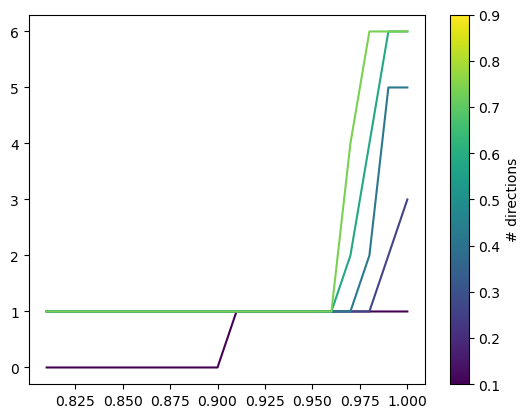

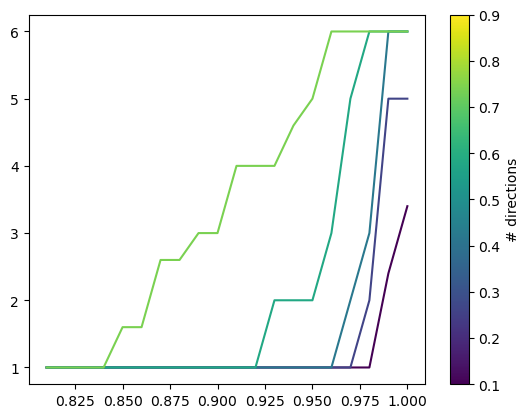

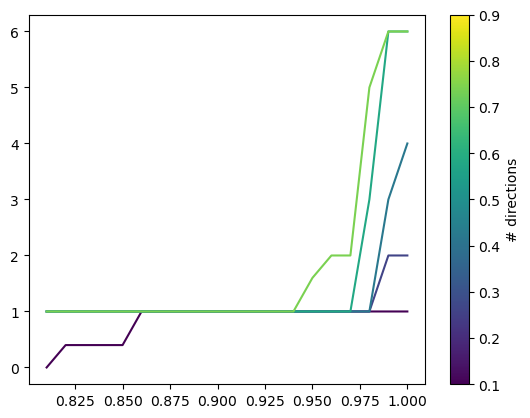

In [75]:
qs = np.array([0.1, .25, .50, .75, .9])#np.linspace(.1, .9, 500)

norm = Normalize(vmin=min(qs), vmax=max(qs))
#cmap = plt.cm.viridis
# Choose a colormap (e.g., 'viridis', 'plasma', 'coolwarm', etc.)
cmap = get_cmap('viridis')

# Generate colors evenly spaced across the colormap
K = qs.shape[0]
#N = results['err'].shape[0]
colors = [cmap(i / K) for i in range(K)]

for m in ['mvcp', 'view_IR', 'view_Raman']:
    for j in range(K):#np.arange(0,results['q'].shape[0],100):

        plt.plot(
            1-alphas, 
            [np.quantile(df_res_all_lis[i][m][0], qs[j]) for i in range(alphas.shape[0])],
            color=colors[j],
            alpha=1
        )
    sm = ScalarMappable(norm=norm, cmap=cmap)
    plt.colorbar(sm, label=r'# directions',ax=None,)
    plt.show()
    
    table_quartiles = pd.DataFrame(np.array([[np.quantile(df_res_all_lis[i][m][0], qs[j]) for i in range(alphas.shape[0])] for j in range(K)]))
    table_quartiles.columns = np.int64(100*(1-alphas))
    table_quartiles = table_quartiles.iloc[:,::-1]
    table_quartiles['quantile'] = qs
    table_quartiles.set_index('quantile')
    table_quartiles

,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100
quantile,,,,,,,,,,,,,,,,,,,,
0.10,0.0,0.4,0.4,0.4,0.4,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
0.25,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0
0.50,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,3.0,4.0
0.75,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,3.0,6.0,6.0
0.90,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.6,2.0,2.0,5.0,6.0,6.0


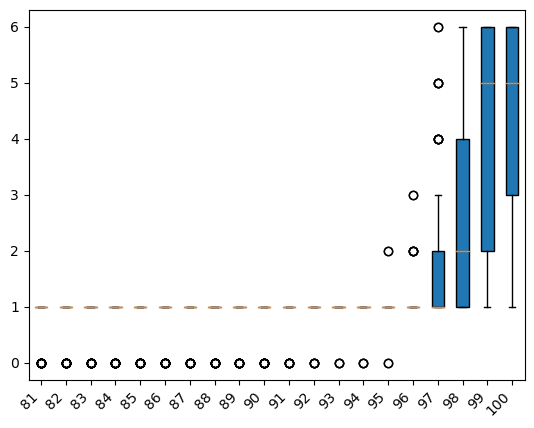

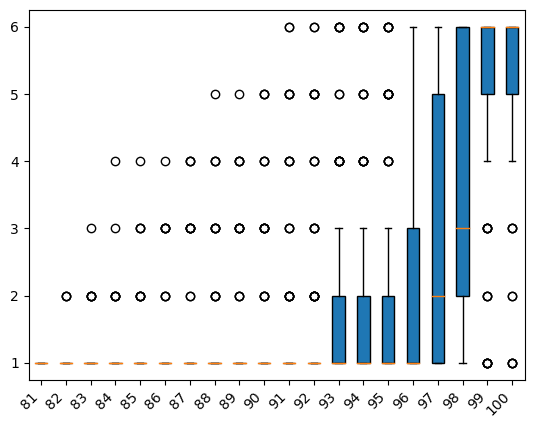

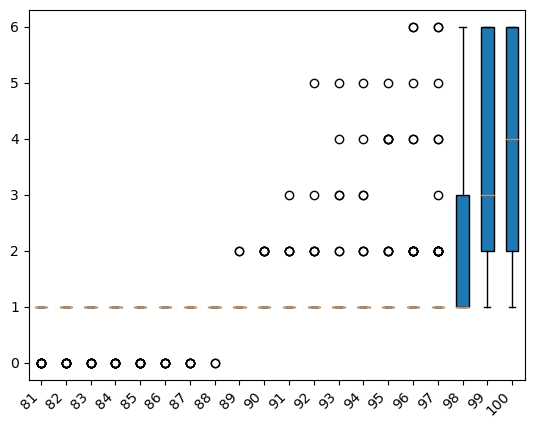

In [56]:
labels = np.int64(100*(1-alphas))[::-1]
for m in ['mvcp', 'view_IR', 'view_Raman']:
    fig, ax = plt.subplots()
    _ = ax.boxplot([df_res_all_lis[i][m][0] for i in range(alphas.shape[0])][::-1],
                   patch_artist=True,
                           labels=labels
               )
    _ = ax.set_xticklabels(labels, rotation=45, ha='right')
    _ = plt.show()
    
    table_boxplot = pd.DataFrame(np.array([df_res_all_lis[i][m][0] for i in range(alphas.shape[0])]).T)
    table_boxplot.columns = np.int64(100*(1-alphas))
    table_boxplot = table_boxplot.iloc[:,::-1]
    table_boxplot
    

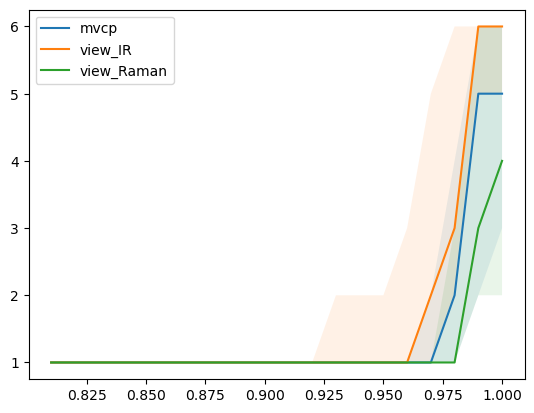

In [77]:
mvcp_median = np.array([np.median(df_res_all_lis[i]['mvcp'][0]) for i in range(alphas.shape[0])])
mvcp_1q = np.array([np.quantile(df_res_all_lis[i]['mvcp'][0], .25) for i in range(alphas.shape[0])])
mvcp_3q = np.array([np.quantile(df_res_all_lis[i]['mvcp'][0], .75) for i in range(alphas.shape[0])])
plt.plot(1-alphas,
         mvcp_median, label='mvcp')
plt.fill_between(1-alphas, mvcp_1q, mvcp_3q, alpha=.1)

mvcp_median = np.array([np.median(df_res_all_lis[i]['view_IR'][0]) for i in range(alphas.shape[0])])
mvcp_1q = np.array([np.quantile(df_res_all_lis[i]['view_IR'][0], .25) for i in range(alphas.shape[0])])
mvcp_3q = np.array([np.quantile(df_res_all_lis[i]['view_IR'][0], .75) for i in range(alphas.shape[0])])
plt.plot(1-alphas,
         mvcp_median, label='view_IR')
plt.fill_between(1-alphas, mvcp_1q, mvcp_3q, alpha=.1)

mvcp_median = np.array([np.median(df_res_all_lis[i]['view_Raman'][0]) for i in range(alphas.shape[0])])
mvcp_1q = np.array([np.quantile(df_res_all_lis[i]['view_Raman'][0], .25) for i in range(alphas.shape[0])])
mvcp_3q = np.array([np.quantile(df_res_all_lis[i]['view_Raman'][0], .75) for i in range(alphas.shape[0])])
plt.plot(1-alphas,
         mvcp_median, label='view_Raman')
plt.fill_between(1-alphas, mvcp_1q, mvcp_3q, alpha=.1)

plt.legend()

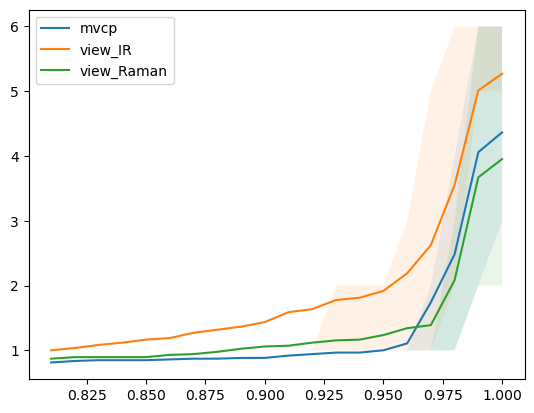

In [7]:
mvcp_median = np.array([np.mean(df_res_all_lis[i]['mvcp'][0]) for i in range(alphas.shape[0])])
mvcp_1q = np.array([np.quantile(df_res_all_lis[i]['mvcp'][0], .25) for i in range(alphas.shape[0])])
mvcp_3q = np.array([np.quantile(df_res_all_lis[i]['mvcp'][0], .75) for i in range(alphas.shape[0])])
plt.plot(1-alphas,
         mvcp_median, label='mvcp')
plt.fill_between(1-alphas, mvcp_1q, mvcp_3q, alpha=.1)

mvcp_median = np.array([np.mean(df_res_all_lis[i]['view_IR'][0]) for i in range(alphas.shape[0])])
mvcp_1q = np.array([np.quantile(df_res_all_lis[i]['view_IR'][0], .25) for i in range(alphas.shape[0])])
mvcp_3q = np.array([np.quantile(df_res_all_lis[i]['view_IR'][0], .75) for i in range(alphas.shape[0])])
plt.plot(1-alphas,
         mvcp_median, label='view_IR')
plt.fill_between(1-alphas, mvcp_1q, mvcp_3q, alpha=.1)

mvcp_median = np.array([np.mean(df_res_all_lis[i]['view_Raman'][0]) for i in range(alphas.shape[0])])
mvcp_1q = np.array([np.quantile(df_res_all_lis[i]['view_Raman'][0], .25) for i in range(alphas.shape[0])])
mvcp_3q = np.array([np.quantile(df_res_all_lis[i]['view_Raman'][0], .75) for i in range(alphas.shape[0])])
plt.plot(1-alphas,
         mvcp_median, label='view_Raman')
plt.fill_between(1-alphas, mvcp_1q, mvcp_3q, alpha=.1)

plt.legend()

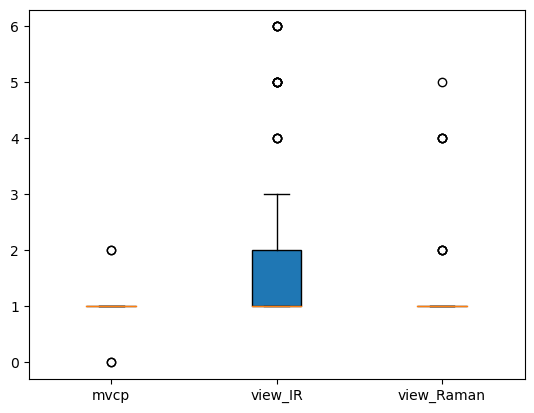

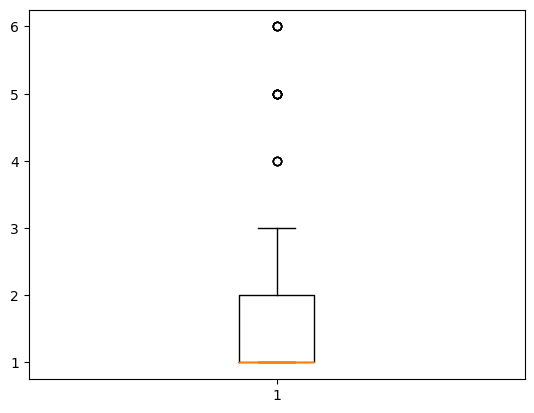

In [222]:
#_ = plt.boxplot(df_res_all_lis[5]['mvcp'][0])
_ = plt.boxplot(df_res_all_lis[5]['view_IR'][0])
#_ = plt.boxplot(df_res_all_lis[5]['view_Raman'][0])

In [114]:
from sklearn.metrics import confusion_matrix

In [115]:
import seaborn as sns

In [185]:
alphas = [0.05]
N_sim = 100

(df_res_lis, 
 df_res_sd_lis,
 df_res_cov_lis, 
 df_res_cov_sd_lis, 
 df_res_all_mean_lis, 
 df_res_cov_all_mean_lis, 
 df_res_all_lis, 
 df_res_cov_all_lis)  = experiment_fig_3(score_list,                                      
                                   label_ir,                                   
                                   quality,
                                   alphas=alphas,
                                   N_sim=N_sim, 
                                   quant_prop=.2, 
                                   cal_prop=0.8, 
                                   seed_init=0)

100%|█████████████████████████████████████████████| 1/1 [00:09<00:00,  9.70s/it]


In [187]:
#[pd.DataFrame({'set_size_mvcp':x, 'set_size_ir':y, 'n':1}) for x,y in zip(df_res_all_lis[0]['mvcp_ideal'], df_res_all_lis[0]['view_IR_ideal'])]
table_set_size_mvcp_IR_ideal = np.int64(np.sum([confusion_matrix(x,y,labels=range(7)) for y,x in zip(df_res_all_lis[0]['mvcp_ideal'], 
                                                                           df_res_all_lis[0]['view_IR_ideal'])], 0))

table_set_size_mvcp_Raman_ideal = np.int64(np.sum([confusion_matrix(x,y,labels=range(7)) for y,x in zip(df_res_all_lis[0]['mvcp_ideal'], 
                                                                           df_res_all_lis[0]['view_Raman_ideal'])], 0))


In [189]:
table_set_size_mvcp_IR_low = np.array(np.sum([confusion_matrix(x,y,labels=range(7)) for y,x in zip(df_res_all_lis[0]['mvcp_low_ir'], 
                                                                           df_res_all_lis[0]['view_IR_low_ir'])], 0))

table_set_size_mvcp_Raman_low = np.array(np.sum([confusion_matrix(x,y,labels=range(7)) for y,x in zip(df_res_all_lis[0]['mvcp_low_ir'], 
                                                                           df_res_all_lis[0]['view_Raman_low_ir'])], 0))


In [194]:
df = pd.DataFrame(table_set_size_mvcp_IR_ideal) / 100


df.index = pd.MultiIndex.from_product([['Raman'], df.index])
df.columns = pd.MultiIndex.from_product([['mvcp'], df.columns])

#table_set_size_mvcp_IR_ideal = pd.DataFrame(table_set_size_mvcp_IR_ideal)
df


mvcp                                     
            0      1     2     3     4     5     6
Raman 0  0.00   0.00  0.00  0.00  0.00  0.00  0.00
      1  0.82  45.78  0.85  0.13  0.00  0.00  0.00
      2  0.15   2.43  0.36  0.05  0.01  0.00  0.00
      3  0.00   0.44  0.05  0.02  0.01  0.00  0.00
      4  0.00   0.17  0.03  0.03  0.04  0.00  0.00
      5  0.00   0.01  0.01  0.03  0.02  0.00  0.00
      6  0.00   0.00  0.00  0.03  0.02  0.07  0.09

<AxesSubplot: xlabel='None-None', ylabel='None-None'>

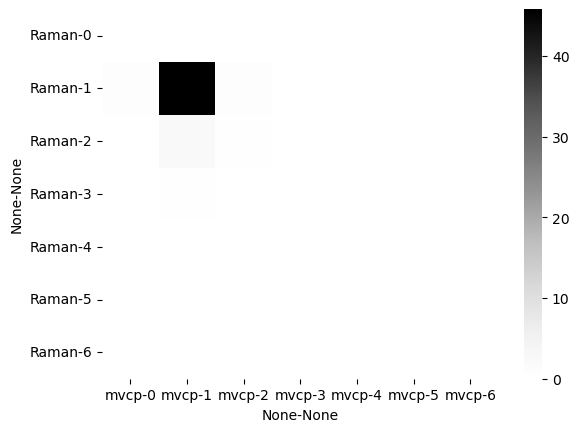

In [195]:
sns.heatmap(df, cmap='Greys')

In [196]:
df = pd.DataFrame(table_set_size_mvcp_Raman_ideal ) / 100


df.index = pd.MultiIndex.from_product([['Raman'], df.index])
df.columns = pd.MultiIndex.from_product([['mvcp'], df.columns])

#table_set_size_mvcp_IR_ideal = pd.DataFrame(table_set_size_mvcp_IR_ideal)
df


mvcp                                     
            0      1     2     3     4     5     6
Raman 0  0.00   0.00  0.00  0.00  0.00  0.00  0.00
      1  0.97  42.81  0.38  0.05  0.00  0.00  0.00
      2  0.00   4.28  0.77  0.02  0.00  0.00  0.00
      3  0.00   0.85  0.07  0.13  0.03  0.00  0.00
      4  0.00   0.59  0.08  0.09  0.07  0.07  0.07
      5  0.00   0.29  0.00  0.00  0.00  0.00  0.02
      6  0.00   0.01  0.00  0.00  0.00  0.00  0.00

<AxesSubplot: xlabel='None-None', ylabel='None-None'>

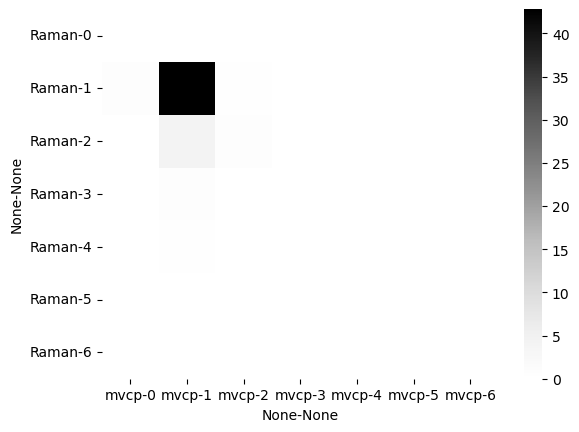

In [197]:
sns.heatmap(df, cmap='Greys')

In [207]:
pd.DataFrame({'n':[x.shape[0] for x,y in zip(df_res_all_lis[0]['mvcp_low_ir'] , df_res_all_lis[0]['view_IR_low_ir'])]})

,n
0,35
1,29
2,36
3,33
4,38
...,...
95,29
96,25
97,37
98,38


In [198]:
np.std([confusion_matrix(x,y,labels=range(7)).sum() for y,x in zip(df_res_all_lis[0]['mvcp_low_ir'], 
                                                                           df_res_all_lis[0]['view_IR_low_ir'])])

4.299709292498738

In [162]:
table_set_size_mvcp_IR_low.sum()

33.349999999999994

In [159]:
table_set_size_mvcp_Raman_low.sum()

32.78

<AxesSubplot: >

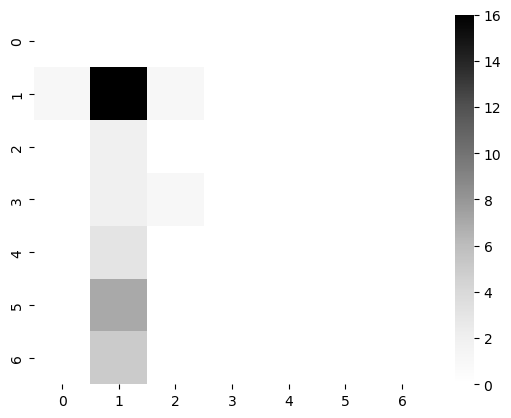

In [128]:
sns.heatmap((table_set_size_mvcp_IR_low), cmap='Greys')

<AxesSubplot: >

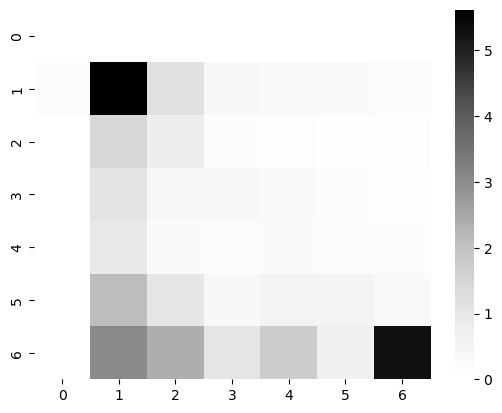

In [184]:
sns.heatmap((table_set_size_mvcp_IR_low), cmap='Greys')

<AxesSubplot: >

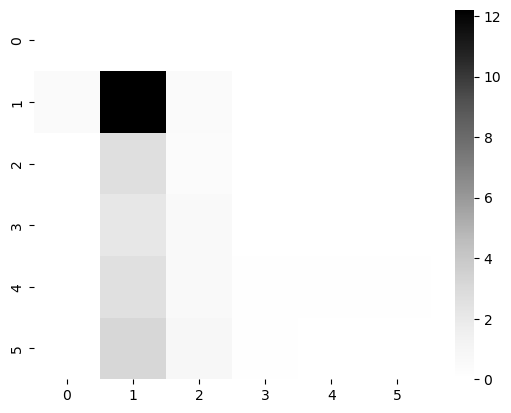

In [170]:
sns.heatmap((table_set_size_mvcp_IR_low)/100, cmap='Greys')

<AxesSubplot: >

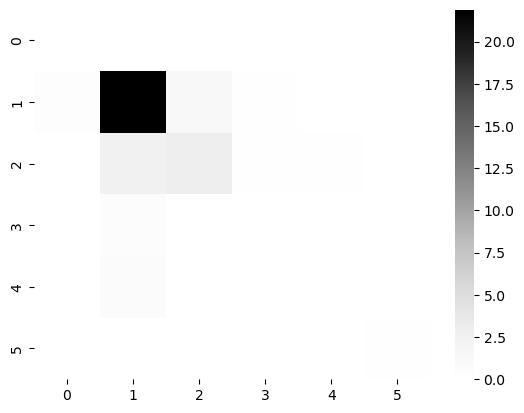

In [178]:
sns.heatmap((table_set_size_mvcp_Raman_low)/100, cmap='Greys')

In [179]:
table_set_size_mvcp_Raman_low

array([[   0,    0,    0,    0,    0,    0],
       [  45, 2189,  131,   26,    9,    2],
       [   7,  257,  298,   28,   21,    9],
       [   3,   54,    7,    5,    4,    1],
       [   2,   74,    4,    4,    5,    6],
       [   0,   17,   10,    2,    5,   19]])

In [174]:
table_set_size_mvcp_Raman_low = np.int64(100*np.mean([confusion_matrix(x,y,labels=range(6)) for y,x in zip(df_res_all_lis[0]['mvcp_low_ir'], 
                                                                           df_res_all_lis[0]['view_Raman_low_ir'])], 0))


In [94]:
[df_res_all_lis[0][k][0] for k in df_res_all_lis[0].keys() if df_res_all_lis[0][k][0].shape[0]>0]

[array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1,
        1, 1, 0, 1, 1, 1]),
 array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1]),
 array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1]),
 array([3, 2, 1, 1, 1, 6, 5, 3, 6, 2, 1, 3, 2, 4, 5, 3, 4, 1, 1, 1, 2, 1,
        2, 4, 4, 2, 5, 1, 4, 1, 1, 1, 5, 5, 6]),
 array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 3,
        5, 1, 1, 1, 1, 1]),
 array([1, 1, 1, 1, 1, 2, 2, 1, 2, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 2, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])]

In [84]:
[(np.mean([np.quantile(x, .9) for x in df_res_all_lis[0][k]]), k) for k in list(df_res_all_lis[0].keys()) if df_res_all_lis[0][k][0].shape[0]>0]


[(1.034, 'mvcp_ideal'),
 (1.9720000000000002, 'mvcp_low_ir'),
 (1.1820000000000002, 'view_IR_ideal'),
 (5.782, 'view_IR_low_ir'),
 (1.777, 'view_Raman_ideal'),
 (2.4770000000000003, 'view_Raman_low_ir')]

In [134]:
[(np.mean([np.max(x) for x in df_res_all_lis[0][k]]), k) for k in list(df_res_all_lis[0].keys()) if df_res_all_lis[0][k][0].shape[0]>0]

[(2.68, 'mvcp_ideal'),
 (3.75, 'mvcp_low_ir'),
 (3.57, 'view_IR_ideal'),
 (5.98, 'view_IR_low_ir'),
 (4.03, 'view_Raman_ideal'),
 (5.13, 'view_Raman_low_ir')]

In [6]:
(ps_list, 
 ps_ir_list, 
 ps_raman_list, 
 env_list, 
 cal_smx_arr, 
 cal_idx_list, 
 q_ir_list, 
 q_raman_list) = envelop_2(score_list, 
                           label_ir,
                         alphas=[0.05],
                         label_table=label_table,
                         N_sim=100, 
                         quant_prop=.2, 
                         cal_prop=0.8, 
                         seed_init=0,
                        quality=quality
                        )

  1%|▍                                          | 1/100 [00:00<00:21,  4.63it/s]

MVCP 1.7142857142857142
IR 2.8285714285714287
Raman 1.8857142857142857
MVCP 2.586206896551724
IR 3.689655172413793
Raman 2.689655172413793


  4%|█▋                                         | 4/100 [00:00<00:15,  6.25it/s]

MVCP 1.5833333333333333
IR 2.361111111111111
Raman 1.6111111111111112
MVCP 1.696969696969697
IR 3.303030303030303
Raman 1.696969696969697


  6%|██▌                                        | 6/100 [00:01<00:16,  5.77it/s]

...

MVCP 1.6666666666666667
IR 2.923076923076923
Raman 1.9743589743589745
MVCP 1.8275862068965518
IR 3.4482758620689653
Raman 1.8620689655172413


 97%|████████████████████████████████████████▋ | 97/100 [00:16<00:00,  6.67it/s]

MVCP 1.24
IR 2.76
Raman 1.8
MVCP 1.2702702702702702
IR 3.189189189189189
Raman 1.6486486486486487


100%|█████████████████████████████████████████| 100/100 [00:16<00:00,  5.89it/s]

MVCP 1.763157894736842
IR 3.1578947368421053
Raman 1.5526315789473684
MVCP 1.8064516129032258
IR 2.6129032258064515
Raman 2.3225806451612905


In [7]:
quality


array(['ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal',
       'ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal',
       'ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal',
       'ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal',
       'ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal',
       'ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal',
       'ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal',
       'ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal',
       'ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal',
       'ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal',
       'ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal',
       'ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal',
       'ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal',
       'ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal', 'ideal',
       'ideal', 'ide

In [12]:
np.quantile(ps_list[5], [.25,.75])

array([1.55800654, 2.        ])

55 1.2222222222222223 2.5555555555555554 2.185185185185185


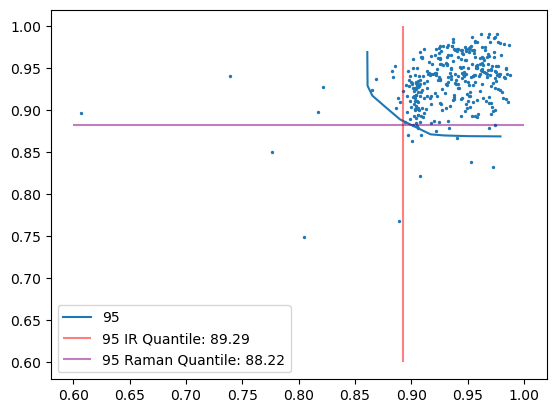

85 1.7575757575757576 3.090909090909091 1.606060606060606


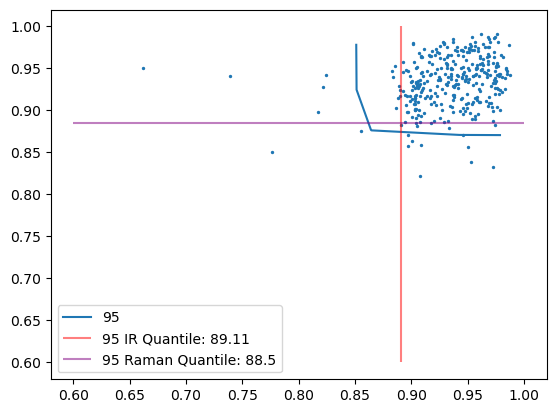

24 2.6666666666666665 3.5555555555555554 2.361111111111111


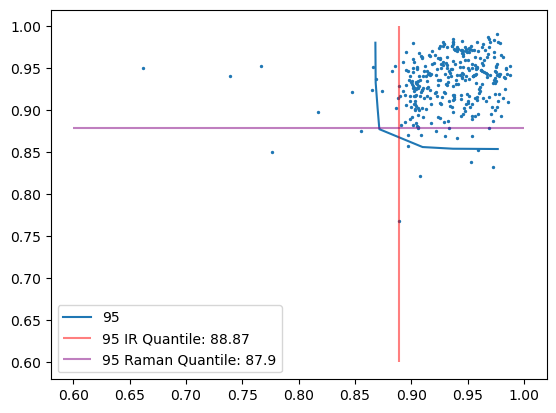

In [13]:
for id_ in [55, 85,24]:#range(100):#(id_1, id_2, id_3):
    #if ps_list[5][id_] > q_1:
    #    continue
    print(id_, ps_list[5][id_], ps_ir_list[5][id_], ps_raman_list[5][id_])
    plt.scatter(1-cal_smx_arr[5][id_][0],
                1-cal_smx_arr[5][id_][1], s=2)

    env_data_list = []
    for env in env_list:
        env_data = pd.DataFrame(1-np.array(env_list[env][id_]).T)
        env_data.columns = ['x - '+str(100-env), 'y - '+str(100-env)]
        _ = plt.plot(env_data['x - '+str(100-env)],
                     env_data['y - '+str(100-env)], label=str(100-env))
        env_data_list.append(env_data)

    q_ir_list, q_raman_list
    _ = plt.vlines(x= 1-q_ir_list[5][id_],
                    ymin=.6,
                    ymax=1,
                    colors='r',
                    alpha=.5,
                    linestyles='solid',
                    label='95 IR Quantile: '+str(round(100*(1-q_ir_list[5][id_]), 2)))

    _ = plt.hlines(y= 1-q_raman_list[5][id_],
                                xmin=.6,
                                xmax=1,
                                colors='purple',
                                alpha=.5,
                                linestyles='solid',
                                label='95 Raman Quantile: '+str(round(100*(1-q_raman_list[5][id_]), 2)))

    _ = plt.legend()
    _ = plt.show()

55 1.2222222222222223 2.5555555555555554 2.185185185185185
85 1.7575757575757576 3.090909090909091 1.606060606060606
24 2.6666666666666665 3.5555555555555554 2.361111111111111


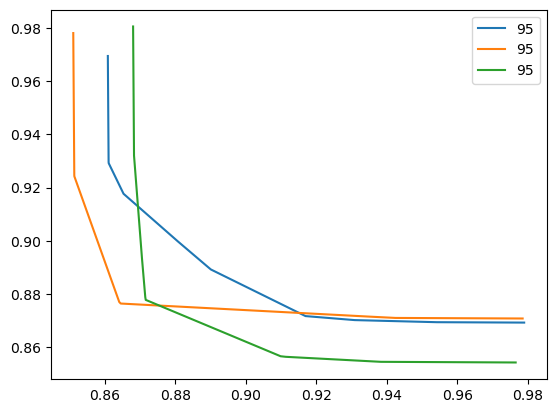

In [15]:
for id_ in [55, 85,24]:#range(100):#(id_1, id_2, id_3):
    #if ps_list[5][id_] > q_1:
    #    continue
    print(id_, ps_list[5][id_], ps_ir_list[5][id_], ps_raman_list[5][id_])
    #plt.scatter(1-cal_smx_arr[5][id_][0],
    #            1-cal_smx_arr[5][id_][1], s=2)

    env_data_list = []
    for env in env_list:
        env_data = pd.DataFrame(1-np.array(env_list[env][id_]).T)
        env_data.columns = ['x - '+str(100-env), 'y - '+str(100-env)]
        _ = plt.plot(env_data['x - '+str(100-env)],
                     env_data['y - '+str(100-env)], label=str(100-env))
        env_data_list.append(env_data)

    q_ir_list, q_raman_list
    #_ = plt.vlines(x= 1-q_ir_list[5][id_],
    #                ymin=.6,
    #                ymax=1,
    #                colors='r',
    #                alpha=.5,
    #                linestyles='solid',
    #                label='95 IR Quantile: '+str(round(100*(1-q_ir_list[5][id_]), 2)))

    #_ = plt.hlines(y= 1-q_raman_list[5][id_],
    #                            xmin=.6,
    #                            xmax=1,
    #                            colors='purple',
    #                            alpha=.5,
    #                            linestyles='solid',
    #                            label='95 Raman Quantile: '+str(round(100*(1-q_raman_list[5][id_]), 2)))

    _ = plt.legend()
    #_ = plt.show()

14 1.2142857142857142 3.0714285714285716 1.3571428571428572


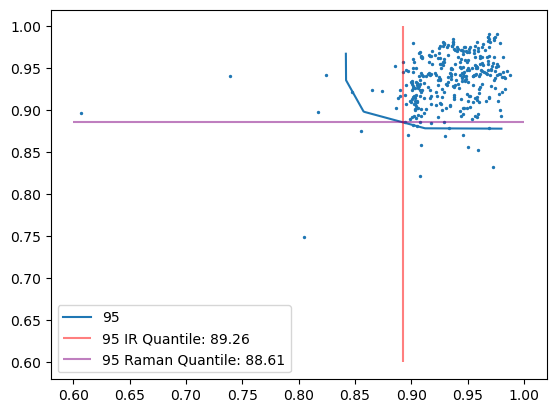

55 1.2222222222222223 2.5555555555555554 2.185185185185185


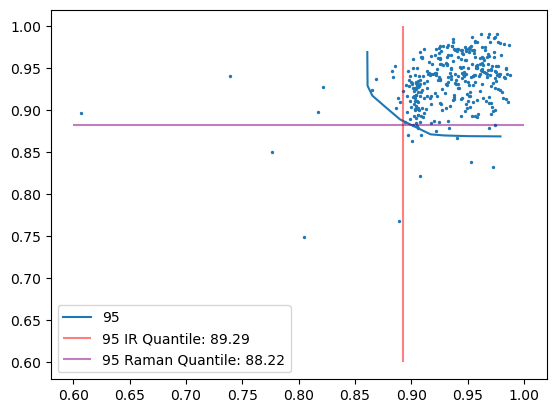

96 1.24 2.76 1.8


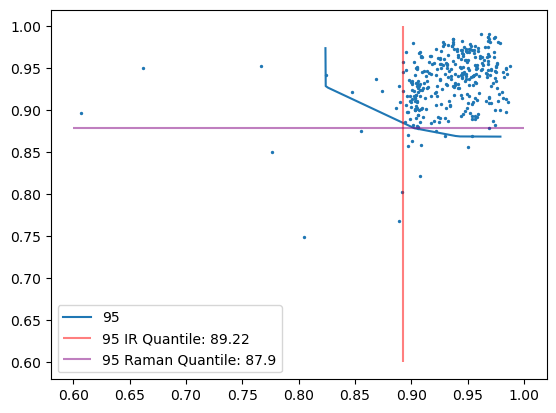

97 1.2702702702702702 3.189189189189189 1.6486486486486487


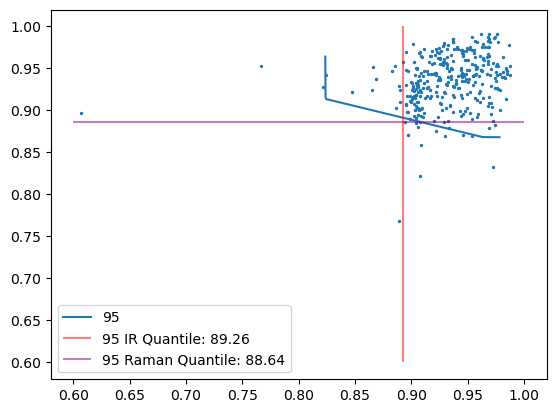

83 1.2903225806451613 2.5806451612903225 1.5806451612903225


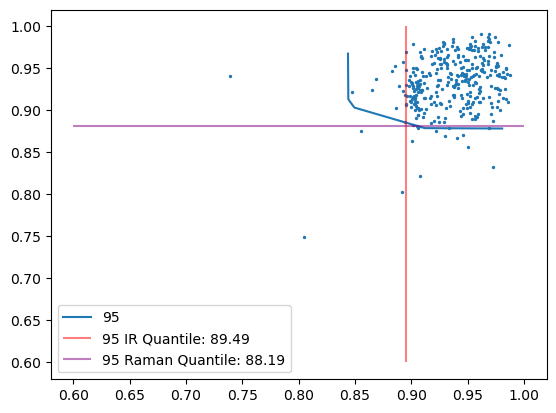

78 1.3 2.4 1.5666666666666667


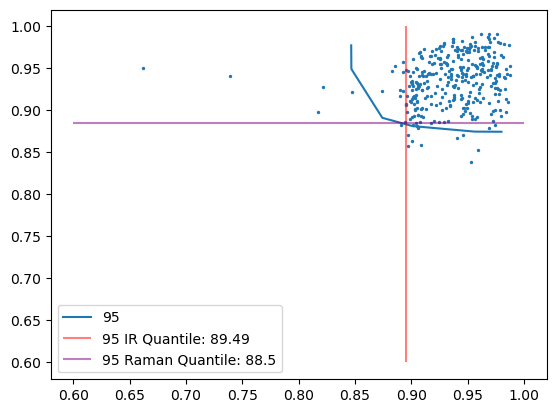

44 1.3125 2.8125 1.84375


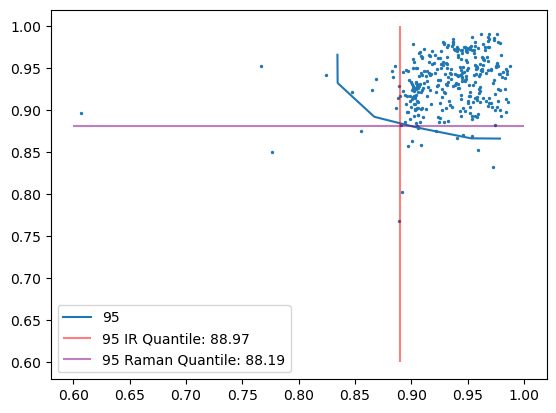

74 1.3636363636363635 2.757575757575758 1.8181818181818181


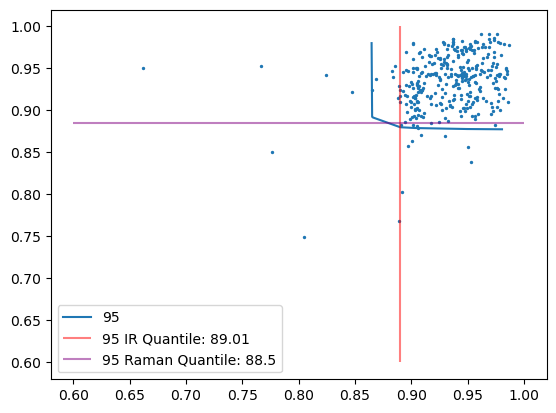

57 1.3888888888888888 2.5833333333333335 1.8888888888888888


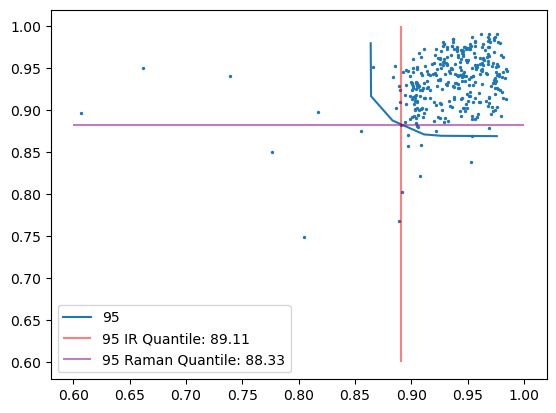

58 1.40625 3.03125 1.84375


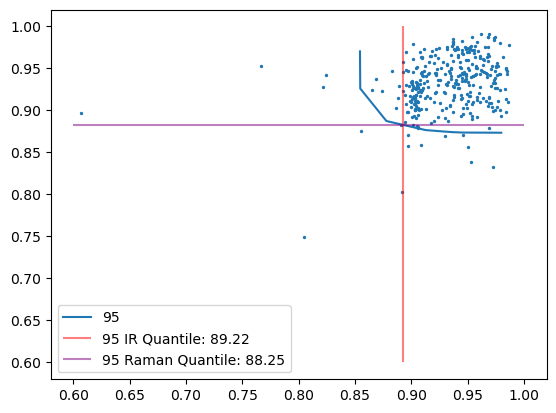

15 1.4242424242424243 3.0303030303030303 2.0606060606060606


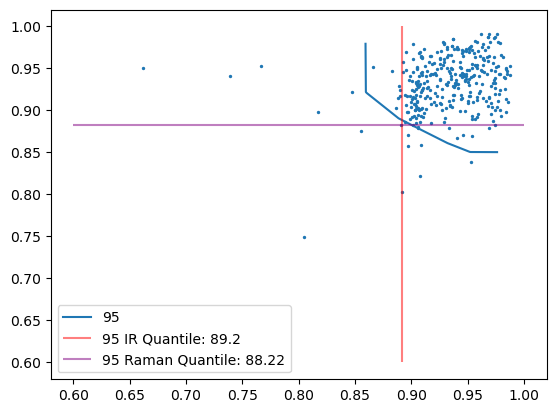

67 1.4333333333333333 2.9 1.6666666666666667


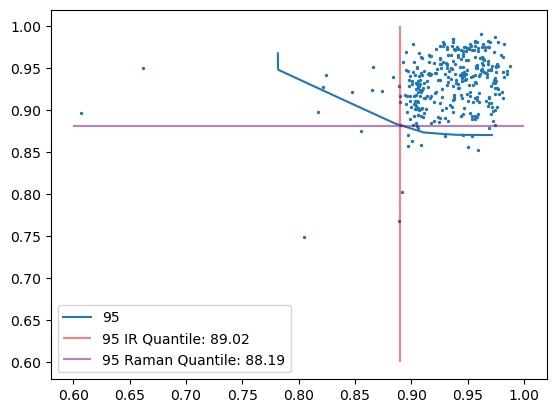

46 1.435897435897436 2.5384615384615383 1.9230769230769231


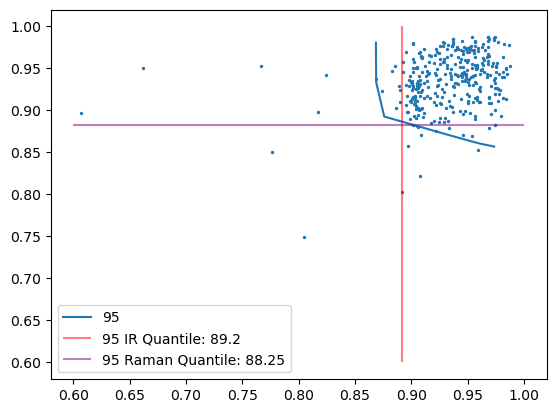

56 1.4444444444444444 2.4444444444444446 2.4074074074074074


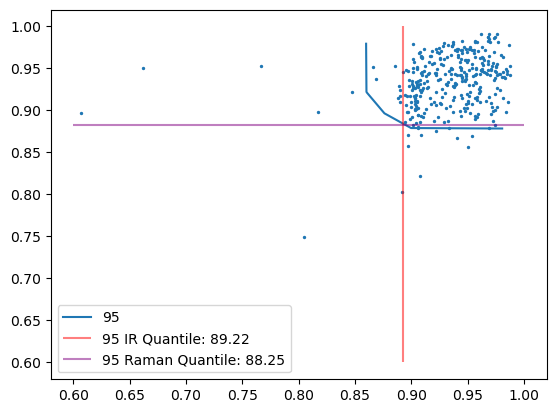

4 1.4473684210526316 2.8421052631578947 1.8421052631578947


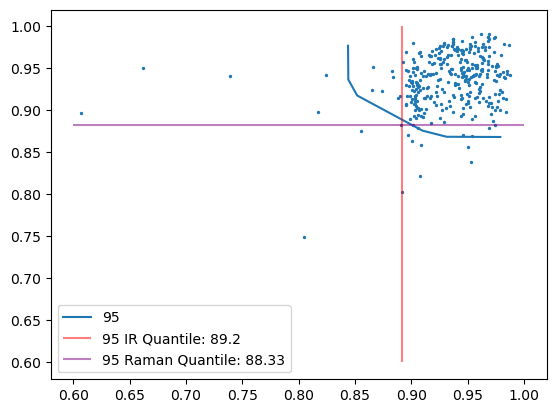

8 1.4838709677419355 1.967741935483871 1.903225806451613


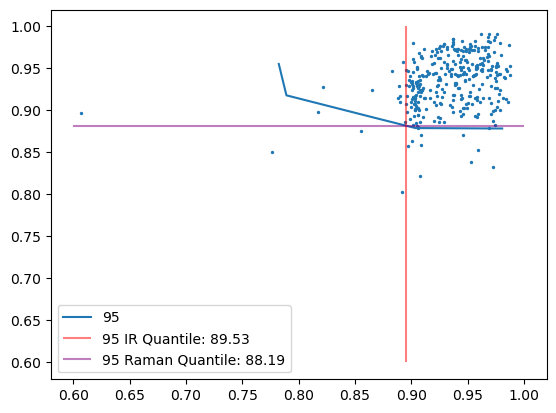

66 1.4864864864864864 2.72972972972973 1.6216216216216217


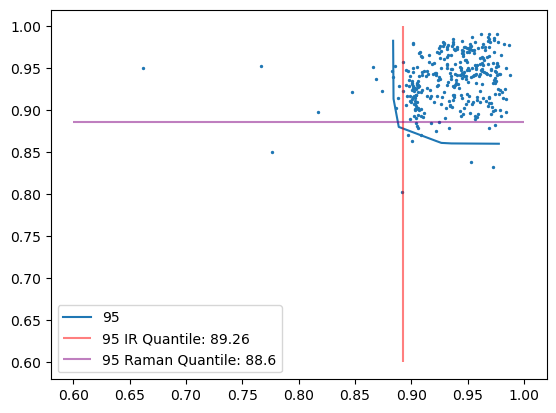

33 1.5142857142857142 2.7142857142857144 2.0


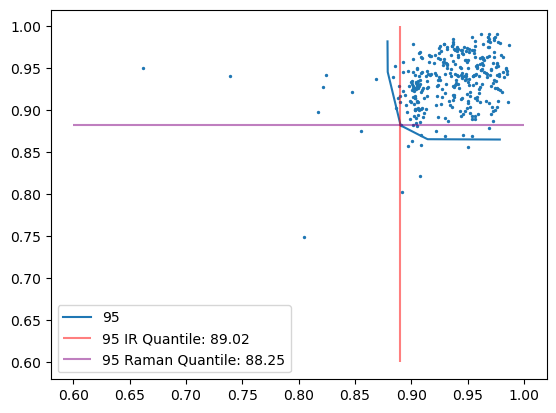

52 1.5151515151515151 2.5757575757575757 2.242424242424242


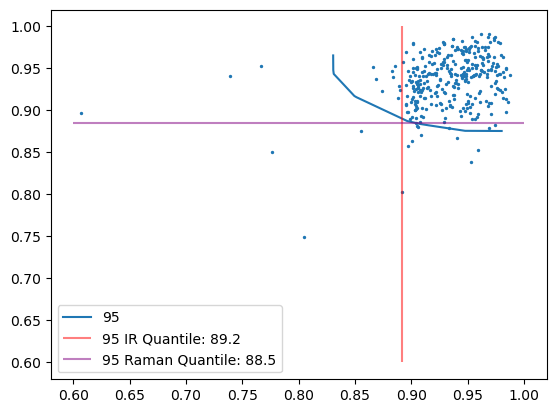

72 1.5151515151515151 2.727272727272727 1.9090909090909092


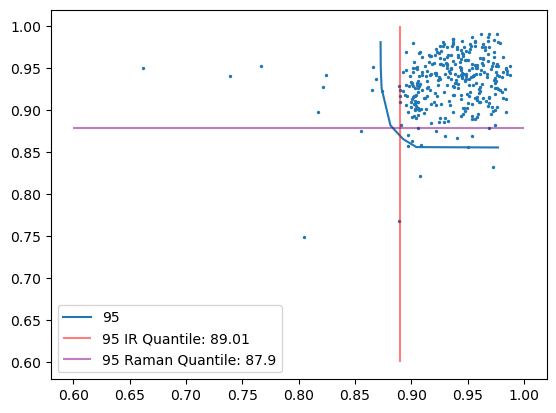

13 1.5161290322580645 2.5483870967741935 1.6451612903225807


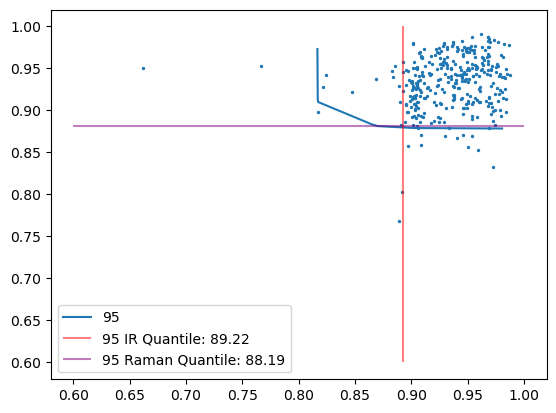

71 1.52 2.2 2.12


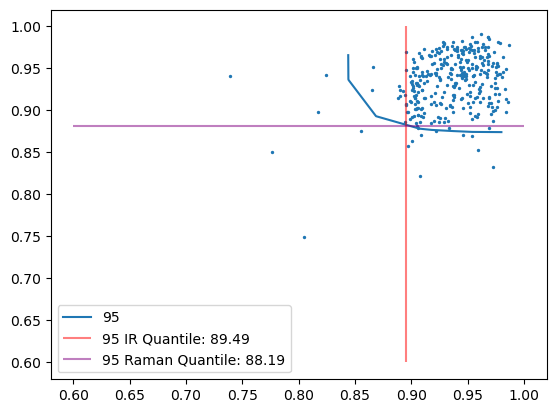

20 1.5333333333333334 2.966666666666667 2.1


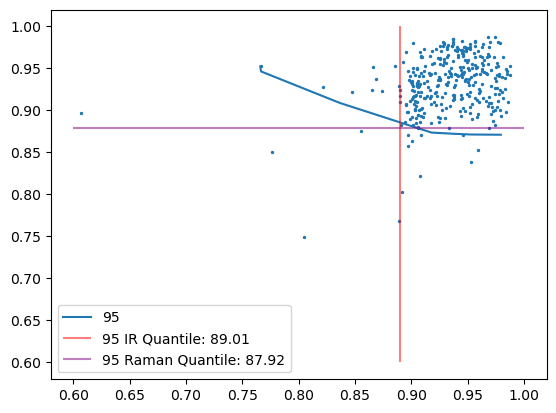

38 1.5454545454545454 2.787878787878788 1.7878787878787878


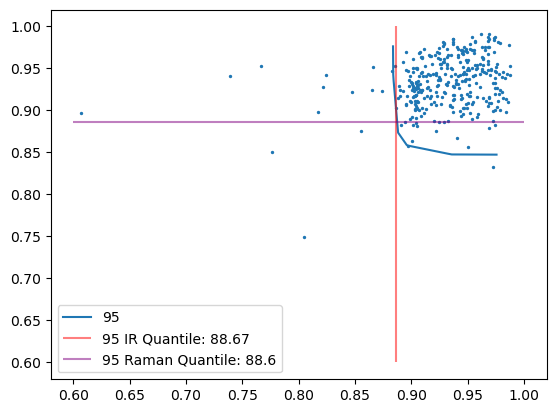

29 1.5555555555555556 3.361111111111111 2.0555555555555554


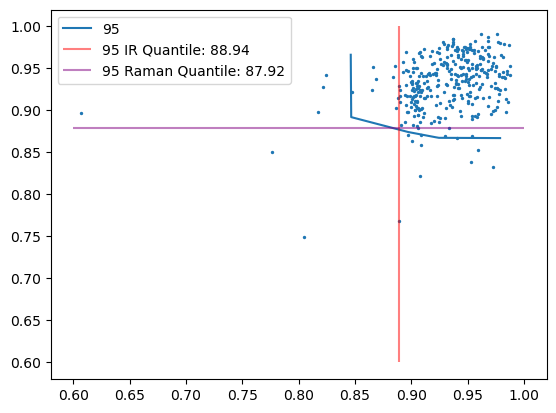

31 1.5588235294117647 2.8529411764705883 1.7647058823529411


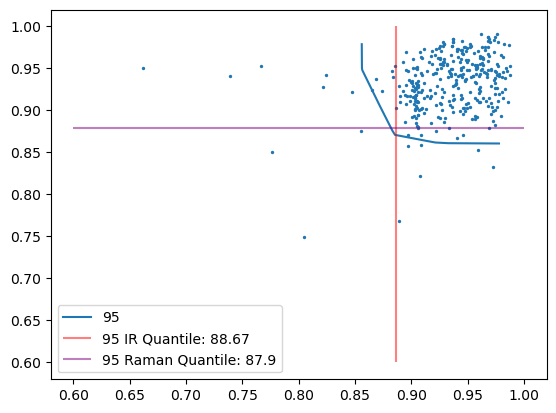

53 1.5625 2.90625 1.5625


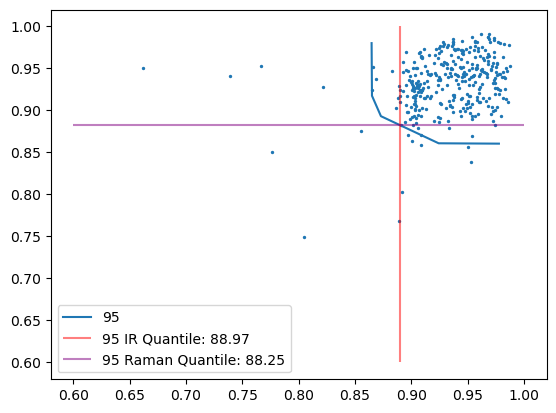

62 1.5666666666666667 1.9666666666666666 1.9333333333333333


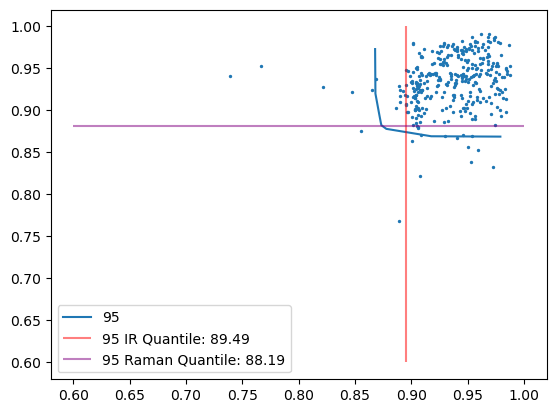

64 1.5714285714285714 2.5357142857142856 2.107142857142857


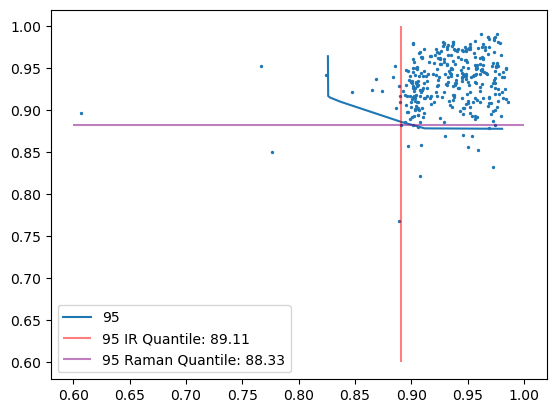

60 1.575 2.925 1.65


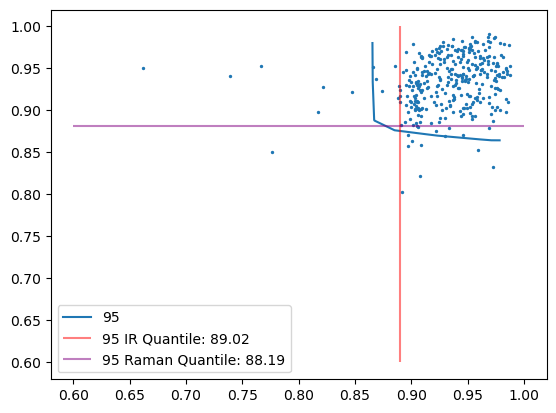

5 1.5757575757575757 3.3333333333333335 1.7272727272727273


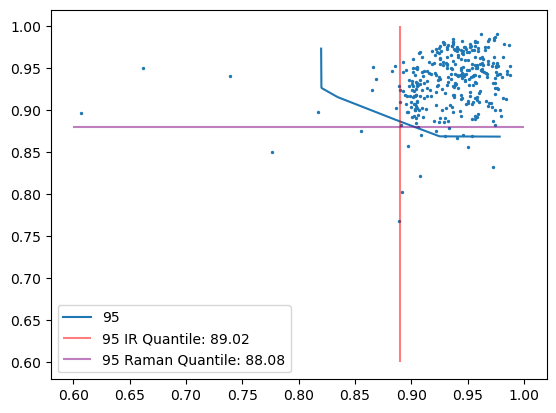

2 1.5833333333333333 2.361111111111111 1.6111111111111112


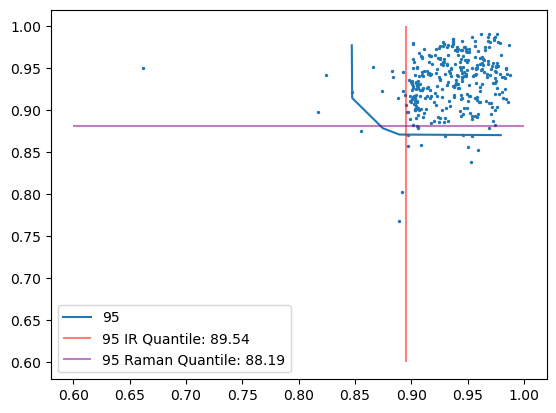

6 1.6388888888888888 2.8333333333333335 1.8055555555555556


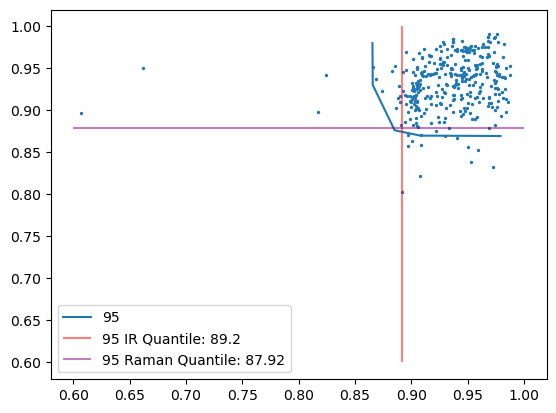

86 1.6388888888888888 2.6666666666666665 1.8333333333333333


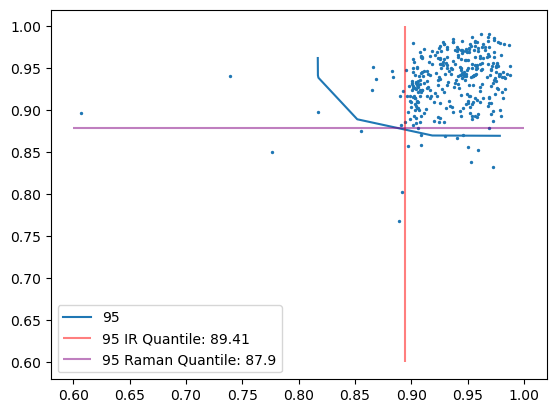

90 1.6571428571428573 2.7142857142857144 1.9428571428571428


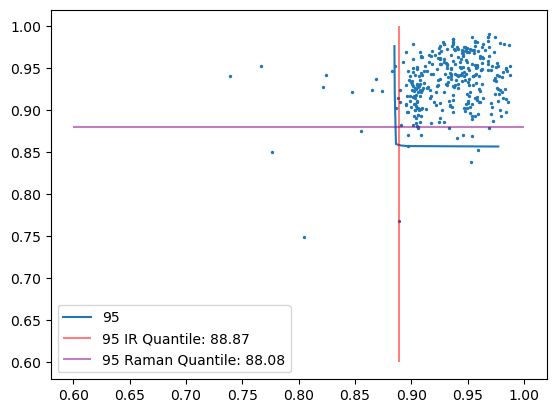

49 1.6666666666666667 3.2564102564102564 1.6153846153846154


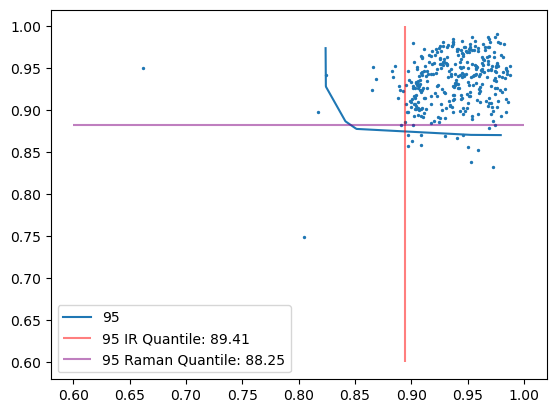

30 1.6666666666666667 2.638888888888889 1.8333333333333333


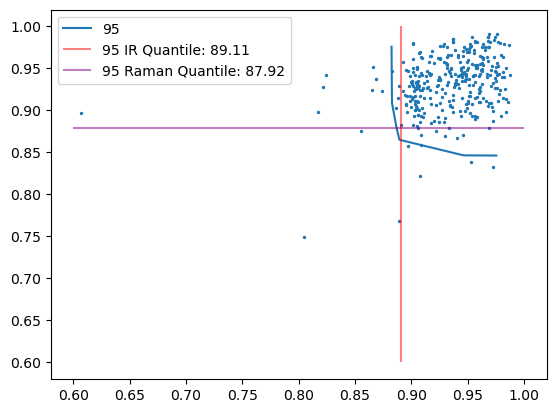

94 1.6666666666666667 2.923076923076923 1.9743589743589745


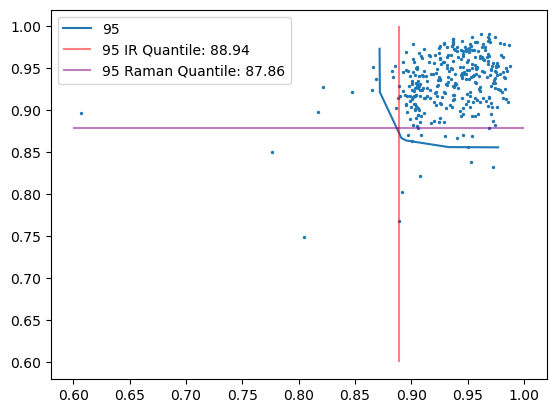

9 1.6666666666666667 3.2666666666666666 1.9666666666666666


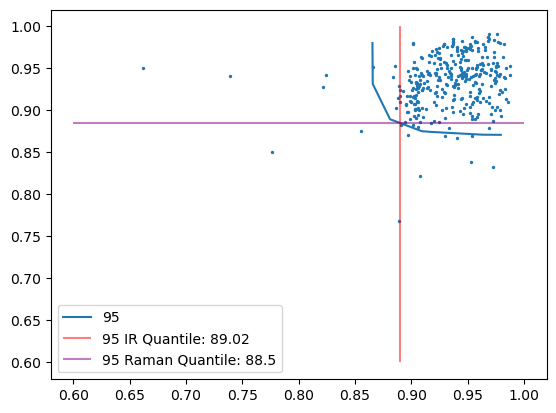

35 1.6666666666666667 2.7777777777777777 1.9444444444444444


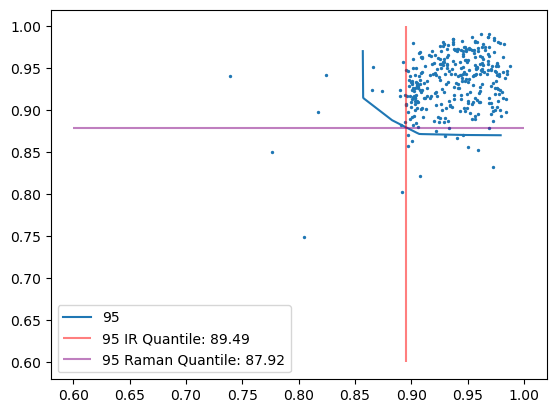

68 1.6666666666666667 3.1666666666666665 1.8333333333333333


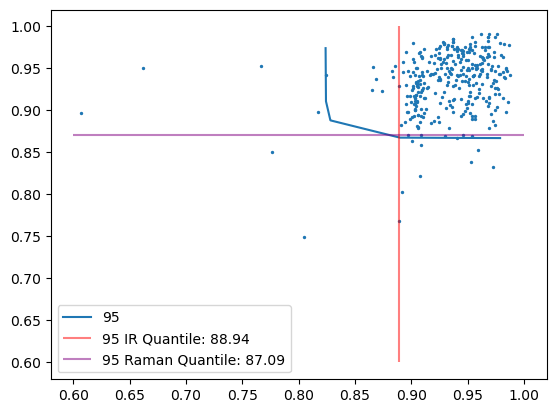

41 1.6857142857142857 2.6857142857142855 1.6857142857142857


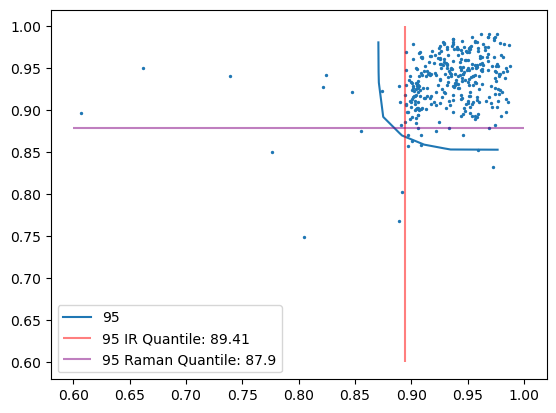

3 1.696969696969697 3.303030303030303 1.696969696969697


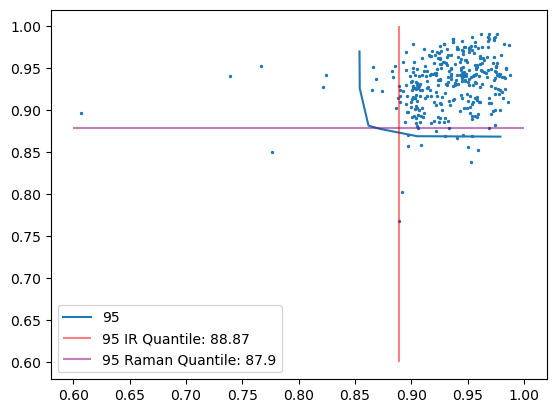

61 1.7 2.8333333333333335 2.0


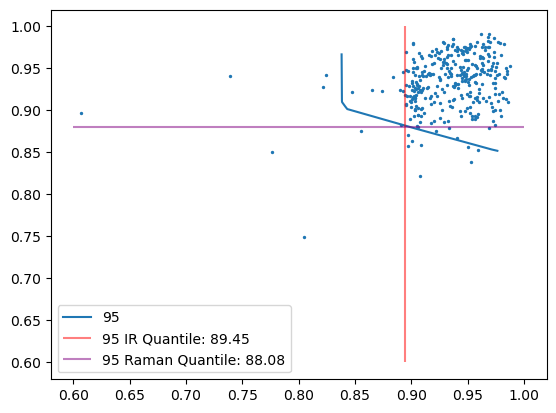

12 1.7037037037037037 2.962962962962963 2.074074074074074


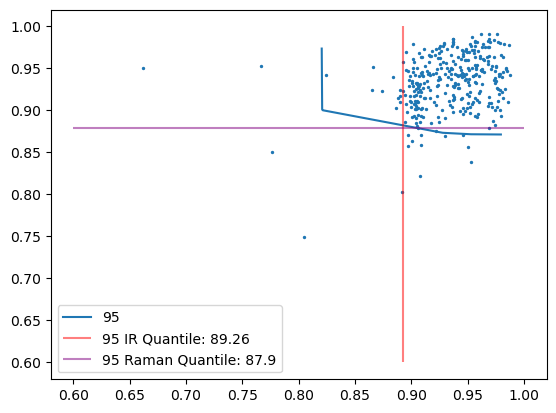

65 1.7073170731707317 3.024390243902439 2.1219512195121952


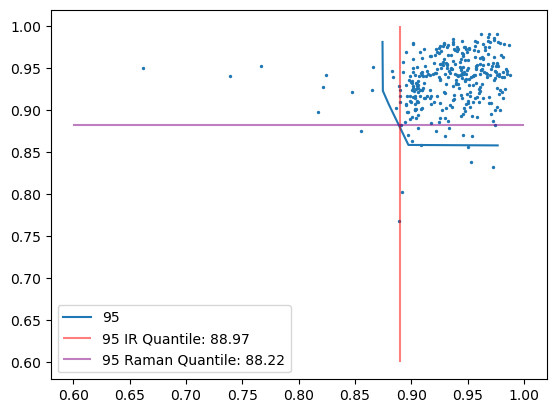

27 1.7096774193548387 2.7096774193548385 1.7419354838709677


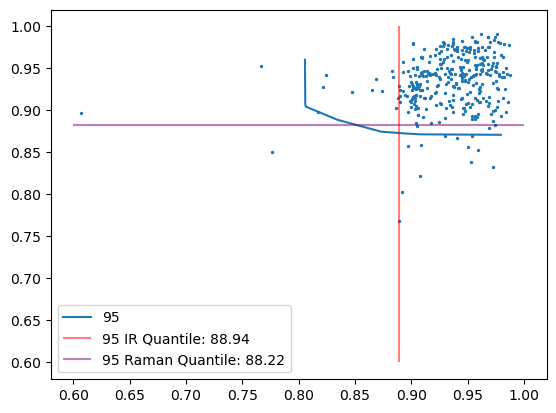

0 1.7142857142857142 2.8285714285714287 1.8857142857142857


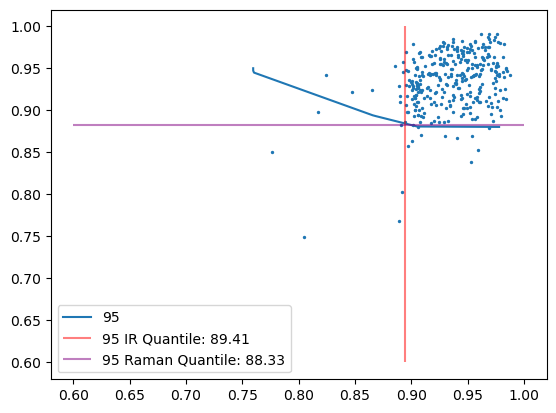

17 1.7142857142857142 3.0285714285714285 1.7428571428571429


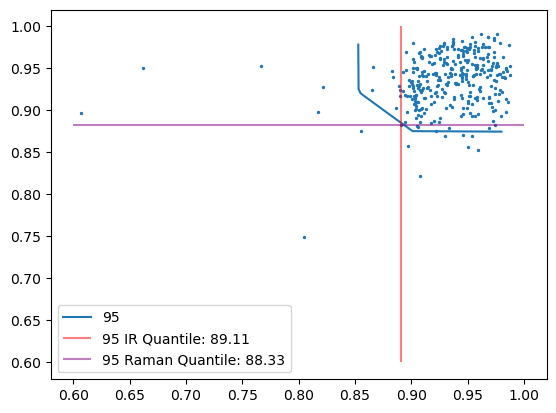

73 1.7333333333333334 2.7 1.6666666666666667


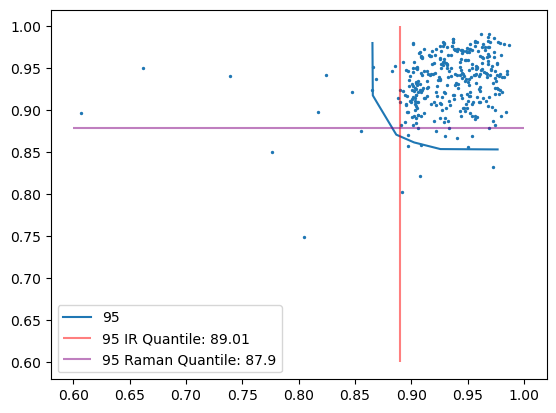

36 1.75 3.15625 1.5


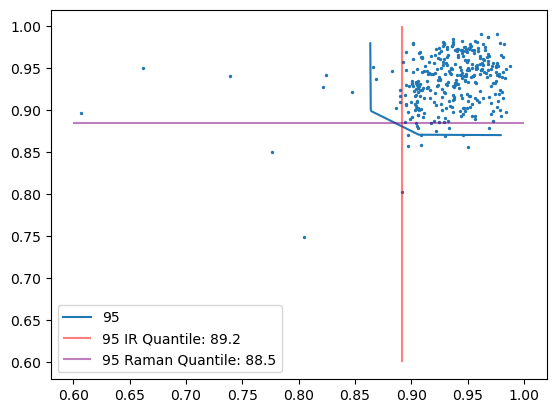

85 1.7575757575757576 3.090909090909091 1.606060606060606


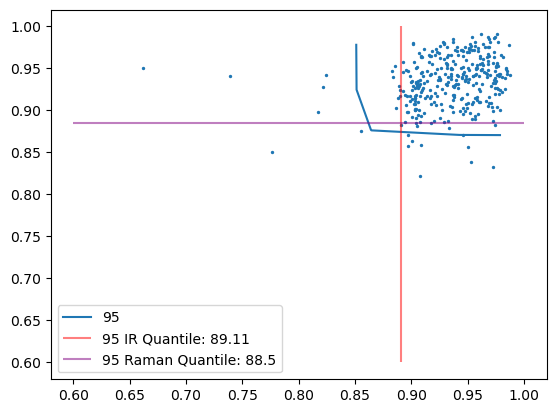

98 1.763157894736842 3.1578947368421053 1.5526315789473684


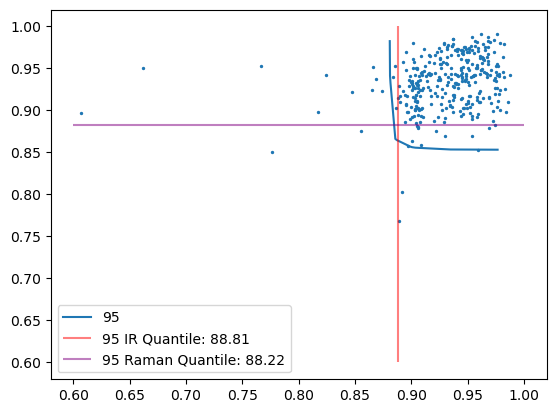

21 1.763157894736842 3.1578947368421053 1.7105263157894737


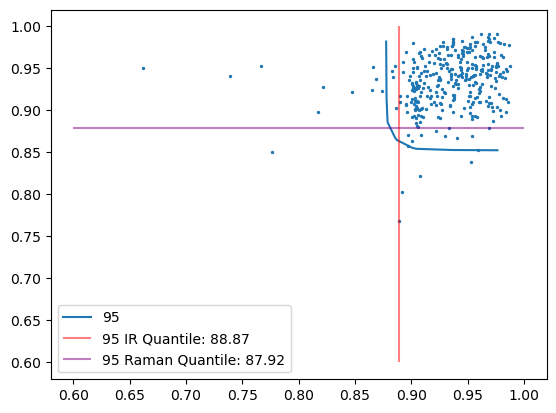

7 1.7741935483870968 2.806451612903226 1.8387096774193548


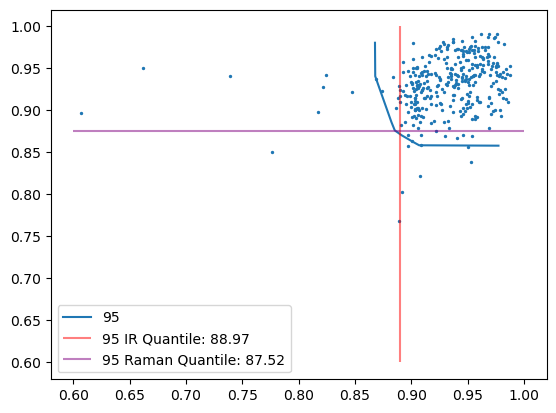

84 1.7741935483870968 3.3225806451612905 2.064516129032258


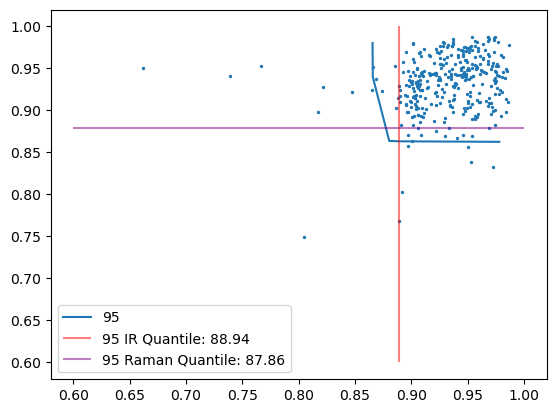

93 1.8 2.914285714285714 1.7142857142857142


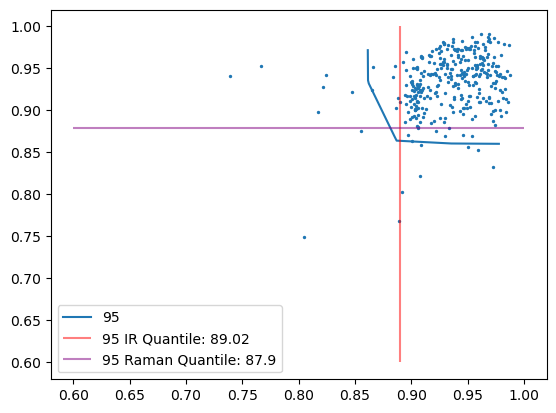

99 1.8064516129032258 2.6129032258064515 2.3225806451612905


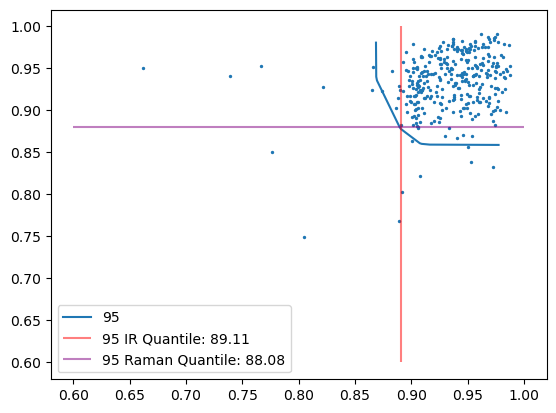

95 1.8275862068965518 3.4482758620689653 1.8620689655172413


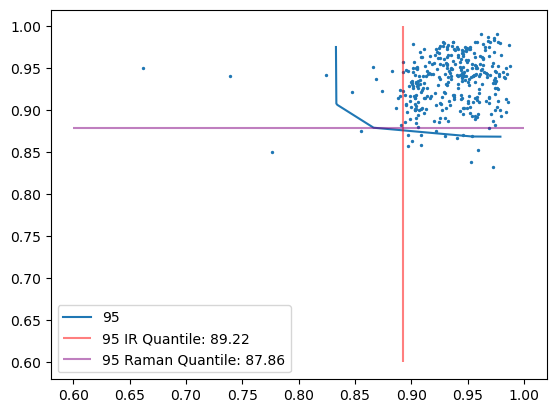

89 1.8285714285714285 3.085714285714286 2.0285714285714285


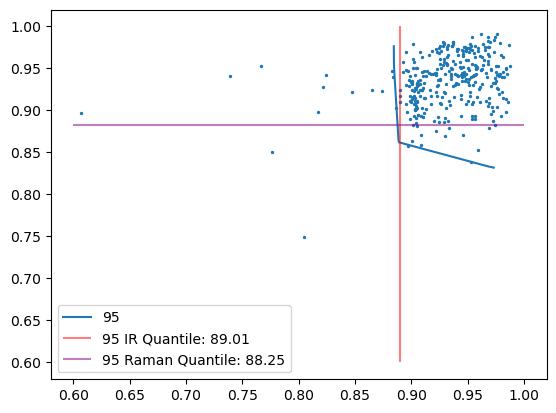

82 1.84375 2.90625 1.78125


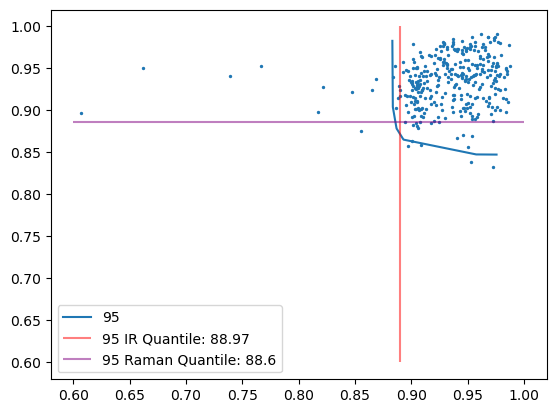

87 1.8571428571428572 2.857142857142857 1.7142857142857142


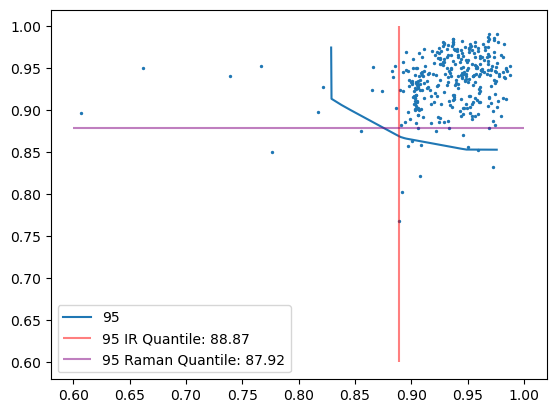

81 1.8571428571428572 3.1785714285714284 1.9285714285714286


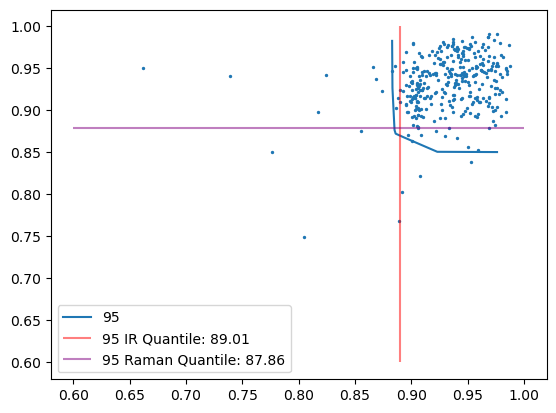

37 1.8620689655172413 3.2758620689655173 2.103448275862069


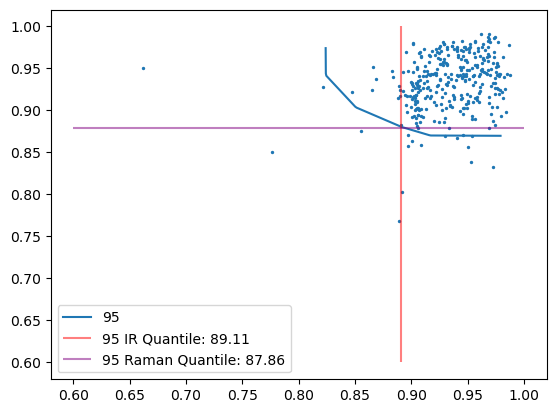

75 1.8620689655172413 3.2758620689655173 1.6206896551724137


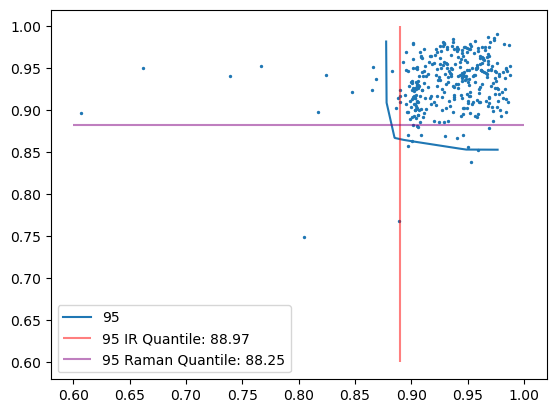

43 1.864864864864865 3.2162162162162162 2.0


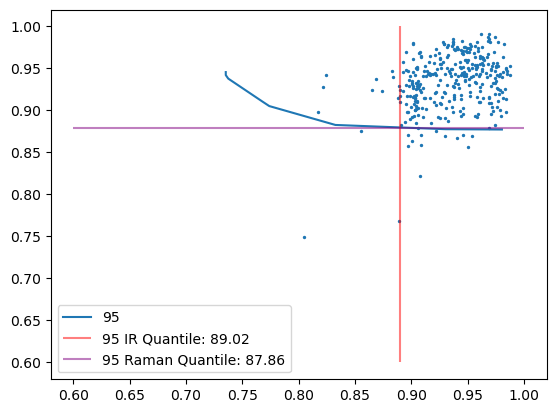

70 1.875 3.3125 1.71875


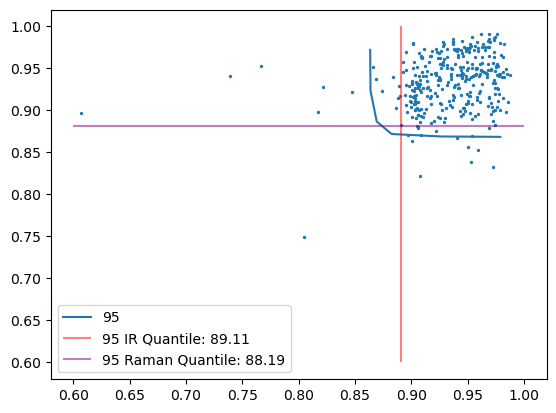

16 1.878787878787879 2.727272727272727 2.4242424242424243


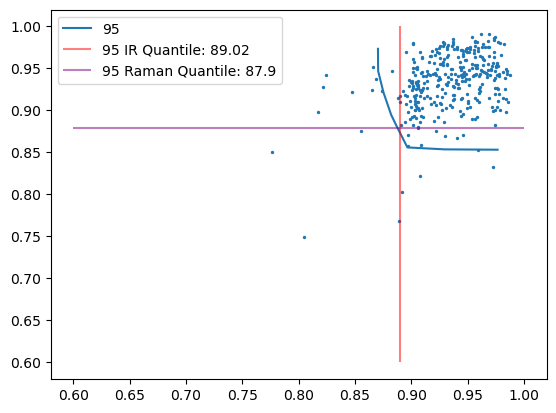

28 1.903225806451613 3.193548387096774 1.8709677419354838


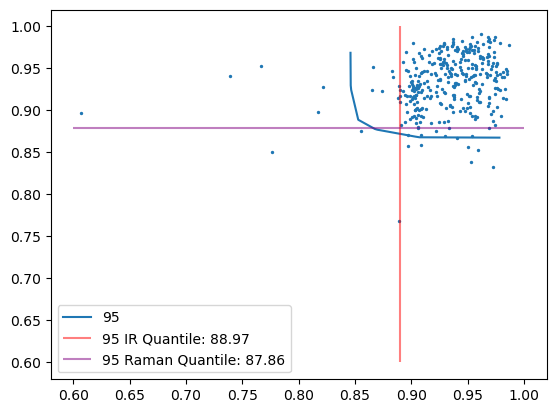

48 1.90625 3.15625 2.1875


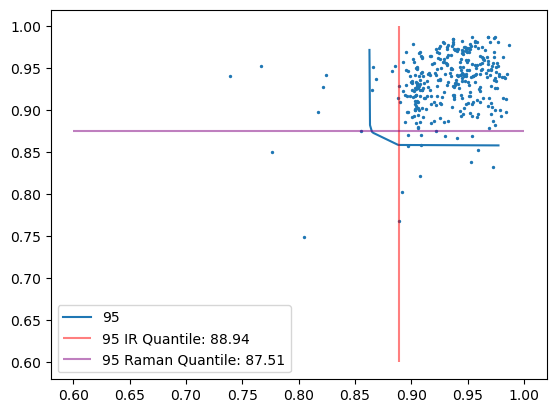

88 1.9268292682926829 3.2195121951219514 1.9268292682926829


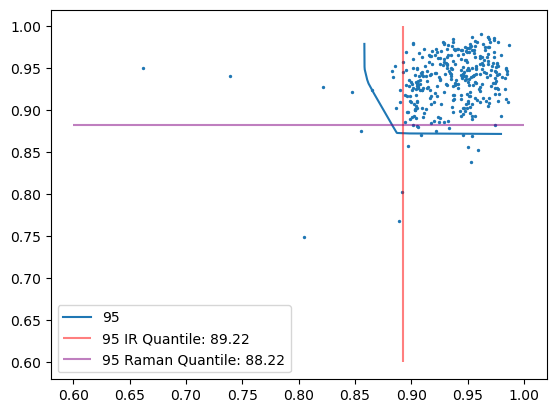

25 1.945945945945946 2.945945945945946 1.8108108108108107


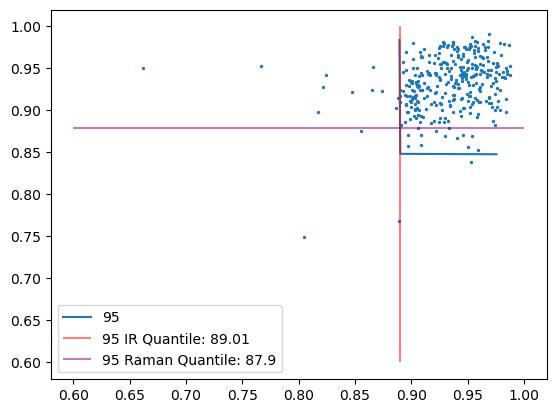

92 1.96 3.4 1.84


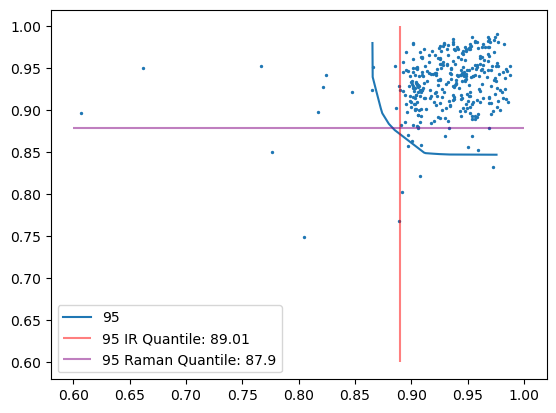

39 1.972972972972973 3.081081081081081 1.9189189189189189


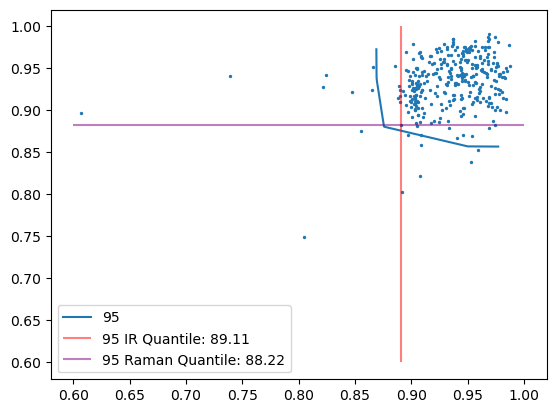

54 2.0 3.4594594594594597 1.864864864864865


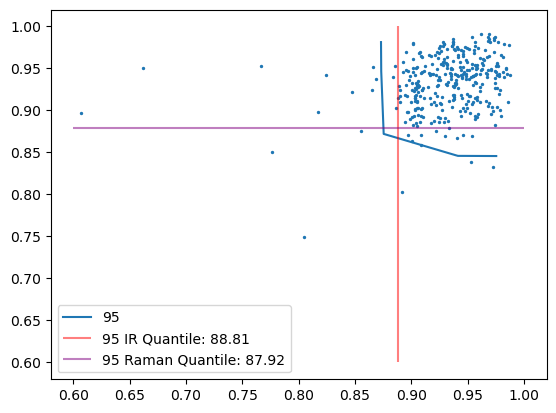

50 2.0 2.96875 2.21875


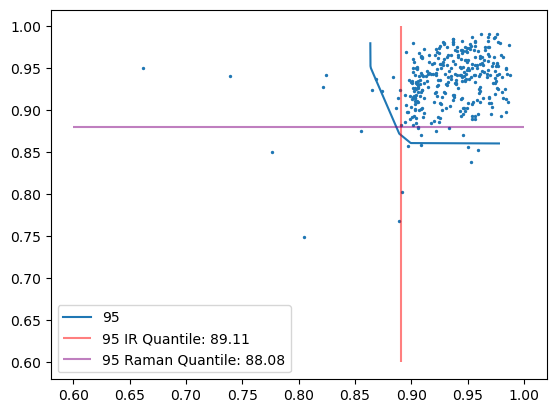

77 2.0 2.90625 2.15625


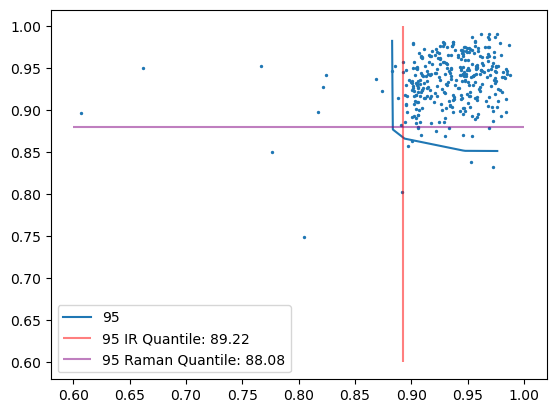

80 2.0 3.1944444444444446 2.0555555555555554


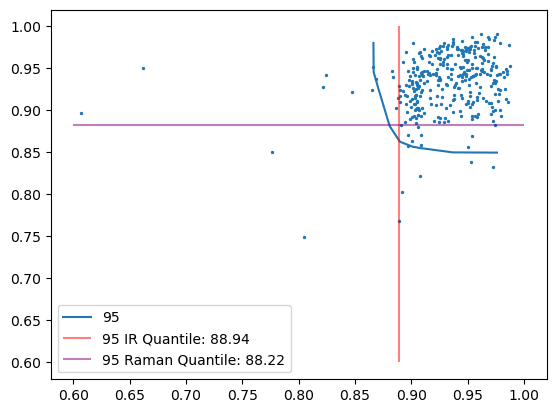

11 2.0303030303030303 3.0 2.5454545454545454


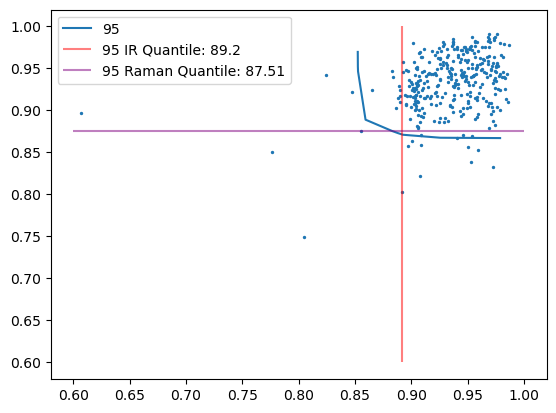

63 2.033333333333333 3.1 1.8333333333333333


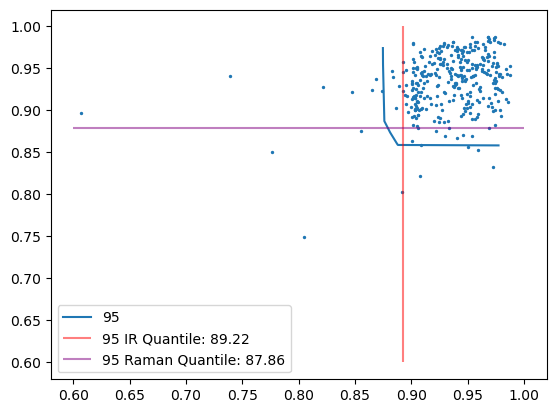

59 2.0476190476190474 2.9761904761904763 2.0714285714285716


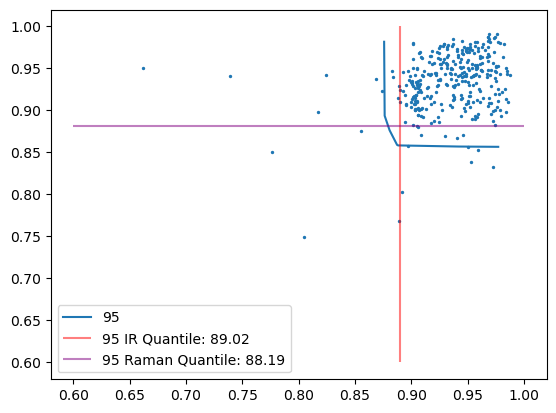

69 2.0555555555555554 3.5 1.9722222222222223


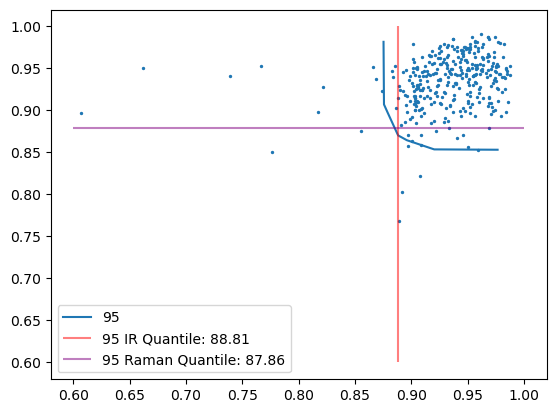

34 2.057142857142857 3.5428571428571427 1.6285714285714286


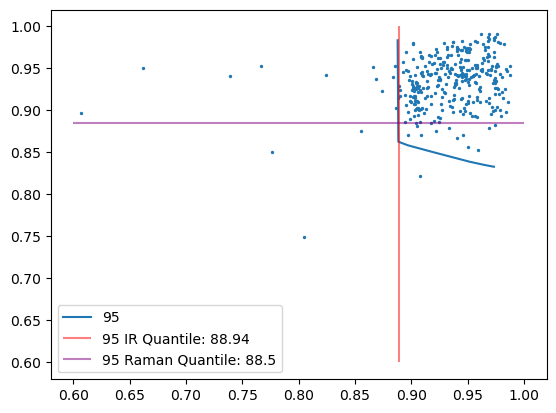

42 2.0606060606060606 2.606060606060606 2.0303030303030303


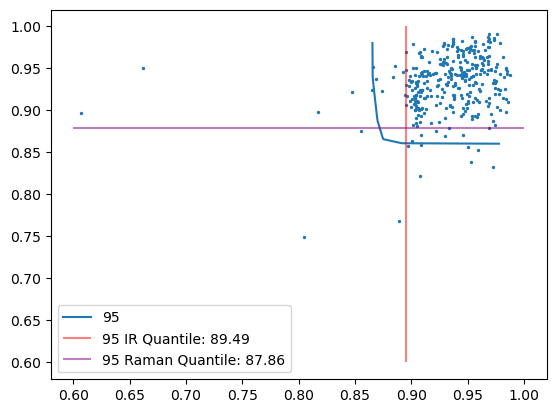

19 2.090909090909091 3.1818181818181817 1.9318181818181819


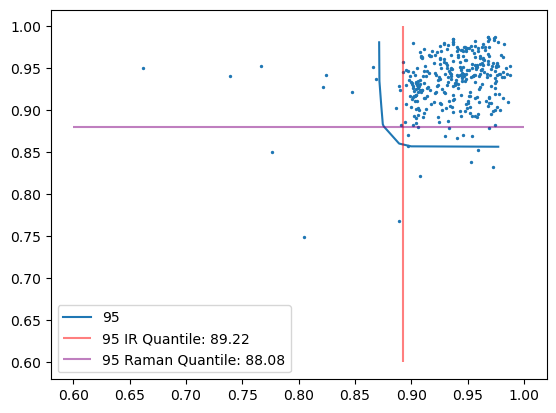

76 2.119047619047619 3.4047619047619047 2.0238095238095237


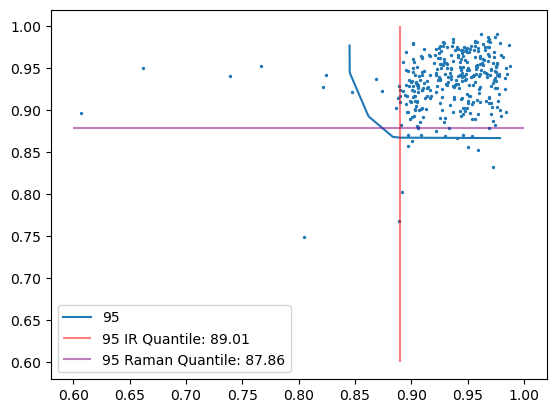

40 2.125 3.40625 2.1875


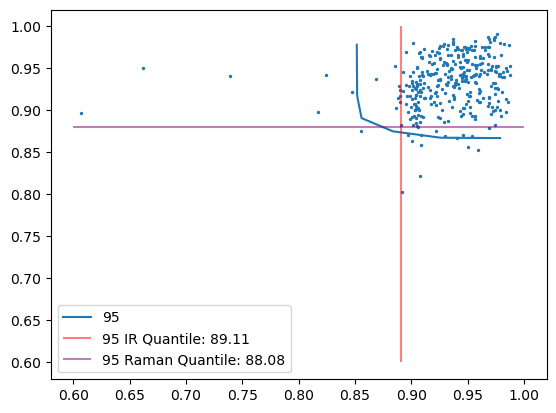

45 2.13953488372093 3.5813953488372094 2.0


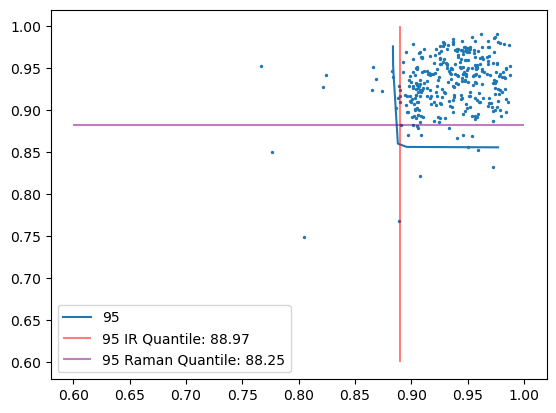

22 2.1578947368421053 3.1315789473684212 2.1315789473684212


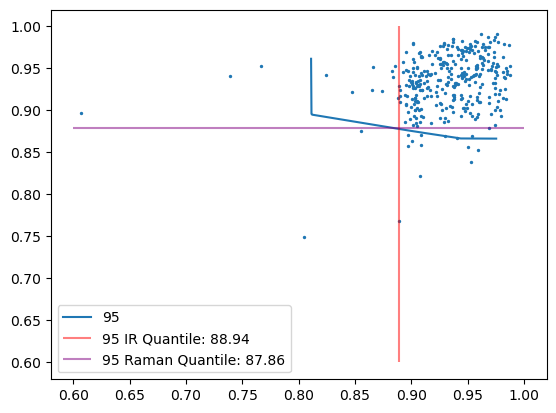

26 2.2083333333333335 2.8333333333333335 2.4166666666666665


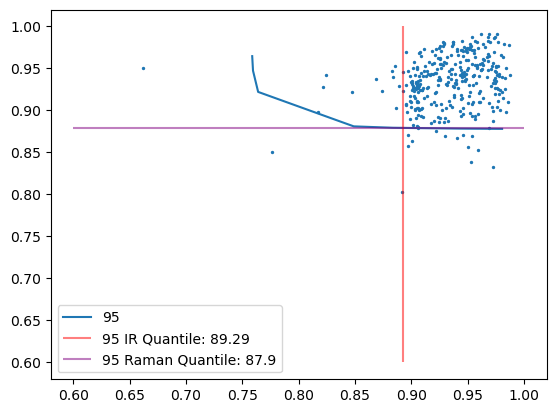

32 2.235294117647059 3.3529411764705883 1.9411764705882353


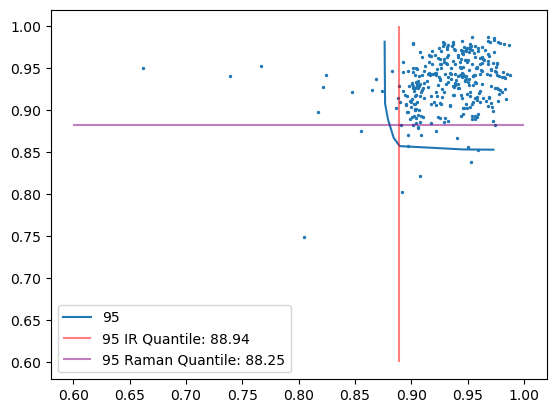

91 2.2580645161290325 3.6451612903225805 1.8387096774193548


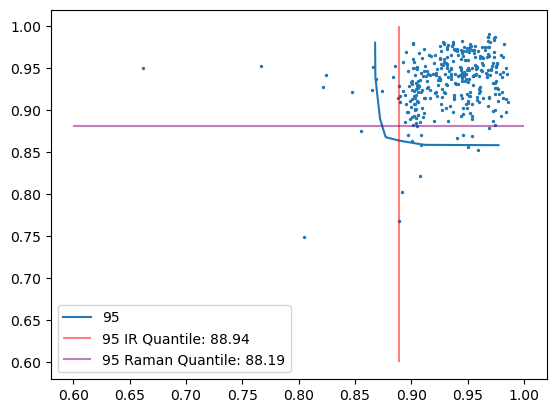

51 2.259259259259259 3.5555555555555554 1.8888888888888888


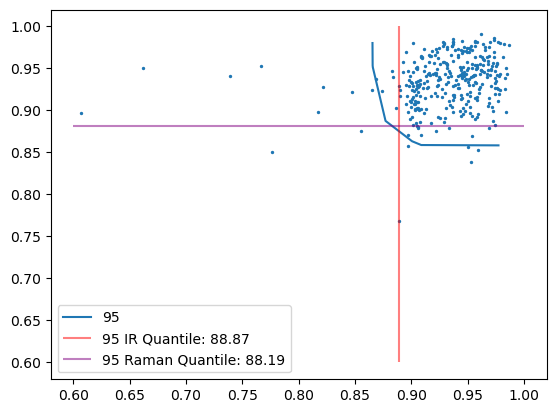

10 2.2941176470588234 3.411764705882353 2.1176470588235294


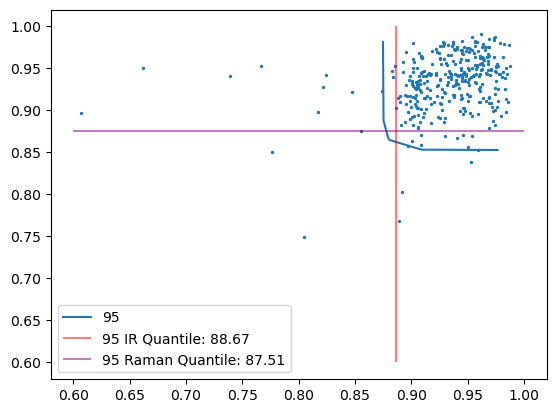

47 2.3 3.3333333333333335 1.6666666666666667


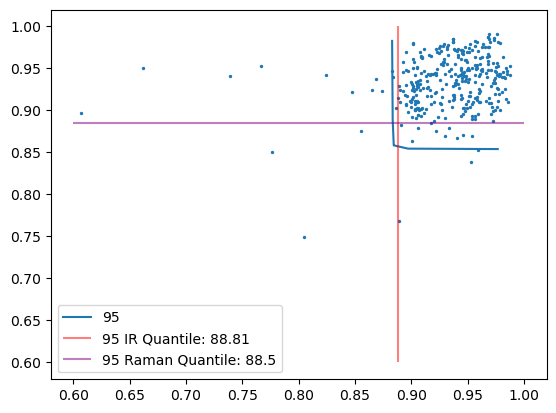

79 2.40625 3.21875 2.0


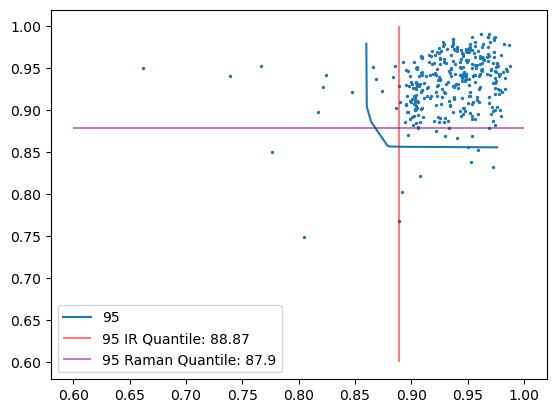

18 2.5789473684210527 3.263157894736842 2.526315789473684


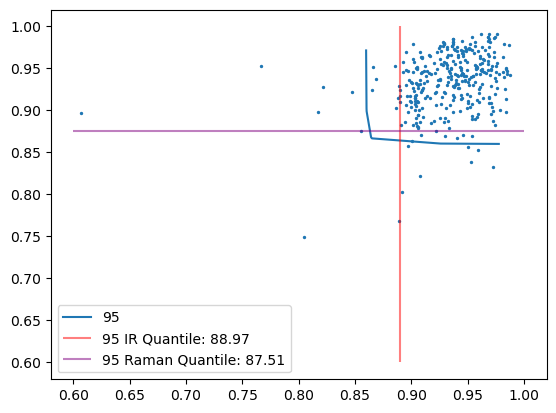

1 2.586206896551724 3.689655172413793 2.689655172413793


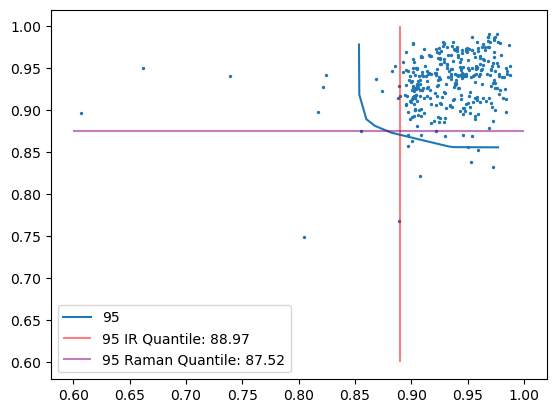

23 2.6176470588235294 3.235294117647059 2.323529411764706


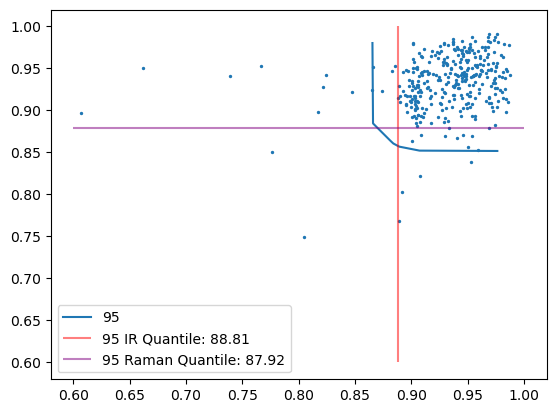

24 2.6666666666666665 3.5555555555555554 2.361111111111111


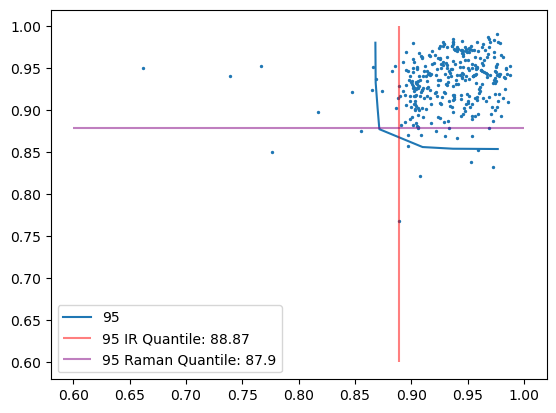

In [10]:
for id_ in np.argsort(ps_list[5]):#range(100):#(id_1, id_2, id_3):
    #if ps_list[5][id_] > q_1:
    #    continue
    print(id_, ps_list[5][id_], ps_ir_list[5][id_], ps_raman_list[5][id_])
    plt.scatter(1-cal_smx_arr[5][id_][0],
                1-cal_smx_arr[5][id_][1], s=2)

    env_data_list = []
    for env in env_list:
        env_data = pd.DataFrame(1-np.array(env_list[env][id_]).T)
        env_data.columns = ['x - '+str(100-env), 'y - '+str(100-env)]
        _ = plt.plot(env_data['x - '+str(100-env)],
                     env_data['y - '+str(100-env)], label=str(100-env))
        env_data_list.append(env_data)

    q_ir_list, q_raman_list
    _ = plt.vlines(x= 1-q_ir_list[5][id_],
                    ymin=.6,
                    ymax=1,
                    colors='r',
                    alpha=.5,
                    linestyles='solid',
                    label='95 IR Quantile: '+str(round(100*(1-q_ir_list[5][id_]), 2)))

    _ = plt.hlines(y= 1-q_raman_list[5][id_],
                                xmin=.6,
                                xmax=1,
                                colors='purple',
                                alpha=.5,
                                linestyles='solid',
                                label='95 Raman Quantile: '+str(round(100*(1-q_raman_list[5][id_]), 2)))

    _ = plt.legend()
    _ = plt.show()

In [8]:
df_res_lis[0]

index,mvcp_ideal,mvcp_low_ir,mvcp_low_raman,view_IR_ideal,view_IR_low_ir,view_IR_low_raman,view_Raman_ideal,view_Raman_low_ir,view_Raman_low_raman
0,1.075679,1.783615,NaN,1.119463,2.988302,NaN,1.340936,1.920069,NaN


In [8]:
df_res_all_mean_lis

[defaultdict(list,
             {'mvcp_ideal': [1.08,
               1.1785714285714286,
               1.1020408163265305,
               1.0384615384615385,
               1.0638297872340425,
               1.0769230769230769,
               0.9795918367346939,
               1.0740740740740742,
               1.1111111111111112,
               1.0,
               1.0392156862745099,
               1.0384615384615385,
               1.1379310344827587,
               1.2592592592592593,
               1.087719298245614,
               1.0384615384615385,
               1.0,
               1.16,
               1.0425531914893618,
               1.1219512195121952,
               1.1090909090909091,
               0.9787234042553191,
               1.0638297872340425,
               1.0980392156862746,
               1.0408163265306123,
               0.9791666666666666,
               1.2622950819672132,
               1.3333333333333333,
               1.0555555555555556,
           

,Set size (mean),TPR (mean),FPR (mean),Set size (standard deviation),TPR (standard deviation),FPR (standard deviation)
coverage,,,,,,
99,2.811383,0.985915,1.0,0.056451,1.338979e-15,0.0
98,2.582767,0.985915,1.0,0.076460,1.338979e-15,0.0
97,2.421621,0.985211,1.0,0.102347,3.085111e-03,0.0
96,2.262925,0.980845,1.0,0.171254,6.794622e-03,0.0
95,2.219289,0.978028,1.0,0.129137,7.026587e-03,0.0
...,...,...,...,...,...,...
5,0.026008,0.080141,0.0,0.005924,1.787124e-02,0.0
4,0.022016,0.067324,0.0,0.006794,1.977514e-02,0.0
3,0.017036,0.052254,0.0,0.007819,2.168097e-02,0.0


In [75]:
[[]][0]

[]

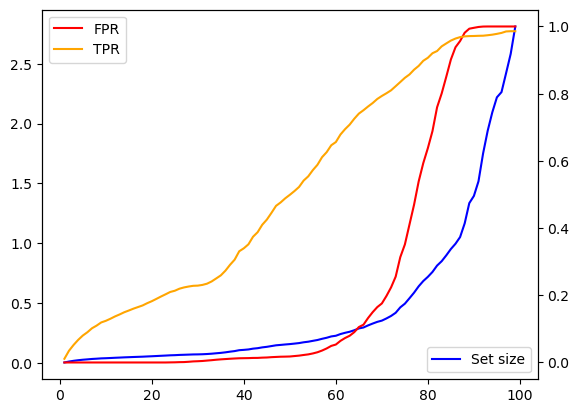